# APRAU 2026/27 — Assignment 1
## Part 1: Exploratory Data Analysis (EDA)

**Dataset:** `dataset_grupo_22.csv` - 2000 patient profiles, 33 *features* and 2 target variables.

### Objective

1. **Descriptive statistics**: data quality, types, measures of central tendency and dispersion.
2. **Univariate analysis**: distribution of each feature and of the two target variables.
3. **Bivariate analysis**: correlation between features and the relationship of each feature with `target_regression` (regression) and `target_class` (classification).
4. **Identify uninformative, constant or redundant features**, with justification.

## 0. Variable dictionary

**Demographic and socioeconomic**

| Variable | Definition in the assignment |
|---|---|
| `age` | Patient chronological age, in years |
| `age_normalized` | Standardized min-max scaling of age |
| `age_level` | Derived age category (Young, Middle, Mature, Senior) |
| `gender` | Biological sex (Male, Female) |
| `education_level` | Highest educational attainment (Primary, Secondary, Tertiary) |
| `employment_status` | Current professional status (Employed, Unemployed, Retired) |

**Anthropometric**

| Variable | Definition in the assignment |
|---|---|
| `bmi` | Body Mass Index, in kg/m² |
| `bmi_level` | WHO-standardized nutritional status (Underweight, Normal, Overweight, Obese) |

**Lifestyle**

| Variable | Definition in the assignment |
|---|---|
| `smoking` | Tobacco consumption status (Never, Former, Current) |
| `physical_activity` | Self-reported weekly exercise intensity (Low, Moderate, High) |
| `stress_level` | Quantified psychological stress tier (Low, Medium, High) |
| `sleep_hours` | Average self-reported daily sleep duration |
| `alcohol_intake` | Metric of habitual alcohol consumption |
| `salt_intake` | Dietary sodium and salt intake estimate |
| `sugar_consumption` | Frequency of refined sugar intake (Low, Medium, High) |
| `family_history` | Familial predisposition to chronic cardiometabolic conditions (Yes, No) |

**Vital signs and haemodynamics**

| Variable | Definition in the assignment |
|---|---|
| `systolic_bp` | Systolic blood pressure, in mmHg |
| `diastolic_bp` | Diastolic blood pressure, in mmHg |
| `blood_pressure` | Aggregated arterial tension measurement |
| `heart_rate` | Resting cardiac frequency, in bpm |
| `systolic_index` | Secondary index capturing haemodynamic pressure dynamics |

**Laboratory biomarkers**

| Variable | Definition in the assignment |
|---|---|
| `HbA1c_level` | Glycated haemoglobin percentage (medium-term glycaemic control) |
| `cholesterol` | Total serum cholesterol |
| `triglycerides` | Serum triglyceride level |
| `hdl` | High-Density Lipoprotein ("good" cholesterol) |
| `ldl` | Low-Density Lipoprotein ("bad" cholesterol) |
| `low_hdl_cholesterol` | Binary indicator for sub-optimal HDL |
| `high_ldl_cholesterol` | Binary indicator for elevated LDL risk |
| `crp_level` | Serum C-Reactive Protein (systemic vascular inflammation marker) |
| `homocysteine_level` | Plasma homocysteine (vascular and metabolic risk indicator) |
| `calcium_baseline` | Biochemical electrolyte baseline recording |
| `plasma_value` | Plasma viscosity variance indicator |
| `ldl_alternative` | Alternative lipid particle profile representation |

## 1. Descriptive statistics

### 1.1 Loading the data and setting up the environment

We start by loading the dataset and fixing the execution environment. We fix the random seed at **22**
so that every result involving randomness is reproducible. The file path is looked up both in the
project root and in the `notebooks` folder, so the notebook works from either of them.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 22

dataset_name = 'dataset_grupo_22.csv'
dataset_candidates = [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f'Could not find {dataset_name}. Run the notebook from the project root '
        'or from the notebooks folder.'
    )

df = pd.read_csv(dataset_path)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Female,Normal,Never,87,0.977,23.600,7.080,176.000,6.500,165.000,High,No,Medium,No,No,146.239,Low,7.897,12.253,113.000,104.000,24.600,14.300,89.000,72.000,92.000,Tertiary,Retired,113.000,9.420,1.415,166.000,90.000,DI_HY
1,Mature,Female,Obese,Never,56,0.621,36.700,8.200,225.756,6.859,254.443,High,No,High,Yes,Yes,149.058,Low,7.313,11.922,133.613,89.786,14.889,8.461,74.660,64.331,127.944,Tertiary,Unemployed,133.613,9.420,0.953,188.000,220.000,DI_HY
2,Mature,Male,Obese,Current,67,0.747,39.800,6.862,290.000,6.300,144.000,High,Yes,Low,No,Yes,148.563,Low,7.561,12.723,119.000,106.000,17.100,7.700,54.000,81.000,161.000,Tertiary,Employed,119.000,9.420,1.077,71.000,172.000,DI_HY
3,Middle,Female,Normal,Current,39,0.425,21.400,6.900,159.000,9.800,193.000,Low,No,Low,Yes,No,150.420,Medium,7.440,12.269,123.000,106.000,2.700,6.400,96.000,35.000,120.000,Secondary,Employed,123.000,9.420,1.579,185.000,92.000,DI_HY
4,Senior,Female,Normal,Never,74,0.828,23.000,7.080,163.000,6.500,88.000,High,No,Low,No,Yes,146.239,Low,7.897,12.253,133.000,96.000,6.400,7.000,99.000,45.000,172.000,Secondary,Retired,133.000,9.420,0.965,131.338,152.000,DI_HY


**Conclusions:** the dataset has **2000 rows and 35 columns** (33 *features* and the 2 target
variables), which matches the 2000-record subset described in the assignment. The first rows already
show a mixture of integer values, decimals and text categories.

### 1.2 Structure, data types and quality

Before any statistical analysis we need to know **what kind of data we are dealing with** and whether
the data is in a fit state to be analysed. We separate the numeric *features* from the categorical
ones, because they require different descriptive techniques.

In [2]:
TARGET_REG, TARGET_CLS = 'target_regression', 'target_class'

num_cols = [c for c in df.select_dtypes(include='number').columns if c != TARGET_REG]
cat_cols = [c for c in df.select_dtypes(exclude='number').columns if c != TARGET_CLS]

print(f'Numeric features ({len(num_cols)}): {num_cols}\n')
print(f'Categorical features ({len(cat_cols)}): {cat_cols}\n')
print('Missing values (total):', df.isna().sum().sum())
print('Duplicated rows:', df.duplicated().sum())

pd.DataFrame({'dtype': df.dtypes.astype(str),
              'n_unique': df.nunique(),
              'missing': df.isna().sum()})

Numeric features (21): ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']

Categorical features (12): ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']

Missing values (total): 0
Duplicated rows: 0


,dtype,n_unique,missing
age_level,object,4,0
gender,object,2,0
bmi_level,object,4,0
smoking,object,3,0
age,int64,72,0
age_normalized,float64,131,0
bmi,float64,487,0
HbA1c_level,float64,110,0
cholesterol,float64,211,0
sleep_hours,float64,217,0


**Conclusions:** there are **21 numeric *features*** and **12 categorical ones**, plus the two target
variables.

There are no **missing values** and no **duplicated rows**, so there will be no need to impute values
or to remove records.

The categorical *features* are stored as text and will have to be **encoded** (ordinal or one-hot)
before any modelling, because linear regression, logistic regression and LDA all operate on numeric
matrices.

### 1.3 Numeric features

For the numeric variables we compute the usual measures of central tendency (mean, median) and of
dispersion (standard deviation, quartiles, minimum and maximum).

The number of distinct values is used to detect constant or near-constant variables.

In [3]:
desc = df[num_cols + [TARGET_REG]].describe().T
desc['cv'] = desc['std'] / desc['mean']
desc['skew'] = df[num_cols + [TARGET_REG]].skew()
desc['kurtosis'] = df[num_cols + [TARGET_REG]].kurt()
desc['n_unique'] = df[num_cols + [TARGET_REG]].nunique()
desc

,count,mean,std,min,25%,50%,75%,max,cv,skew,kurtosis,n_unique
age,2000.000,55.191,20.286,18.000,38.000,57.000,73.000,89.000,0.368,-0.160,-1.146,72
age_normalized,2000.000,0.611,0.233,0.184,0.414,0.632,0.816,1.000,0.381,-0.160,-1.146,131
bmi,2000.000,27.807,7.180,15.000,21.800,27.535,33.700,59.450,0.258,0.107,-0.701,487
HbA1c_level,2000.000,6.846,0.573,3.500,6.817,6.943,7.011,9.000,0.084,-1.416,9.654,110
cholesterol,2000.000,225.051,41.294,150.000,191.000,225.373,258.000,299.000,0.183,-0.011,-1.017,211
sleep_hours,2000.000,7.047,1.631,4.000,5.700,7.012,8.400,10.000,0.231,-0.014,-1.011,217
triglycerides,2000.000,158.239,65.382,50.000,104.000,151.000,209.000,399.000,0.413,0.436,0.021,310
blood_pressure,2000.000,150.145,5.221,120.000,149.058,149.974,151.266,180.000,0.035,-0.584,14.173,140
crp_level,2000.000,7.375,1.100,0.011,7.277,7.458,7.706,14.615,0.149,-0.306,14.981,191
homocysteine_level,2000.000,12.379,1.123,5.110,12.253,12.417,12.621,19.874,0.091,-0.683,19.018,191


**Conclusions.**

- **`calcium_baseline` is a constant *feature***, with a standard deviation of exactly 0, a coefficient
  of variation of 0 and **a single distinct value** (9.42) across the 2000 rows. A variable that does
  not vary cannot explain the variation of anything.
- **There are signs of redundancy.** `systolic_bp` and `systolic_index` have exactly the same
  descriptive statistics. The same happens between `ldl` and `ldl_alternative`, and between `age` and
  `age_normalized` (which, by the assignment's definition, is a rescaling of age). We will confirm in
  the bivariate analysis whether they are **redundant**.
- `HbA1c_level`, `blood_pressure`, `crp_level` and `homocysteine_level` have a very narrow IQR relative
  to their full range (for example `blood_pressure`: IQR ≈ 149–151, range 120–180). This indicates
  highly concentrated distributions, with long tails and high kurtosis.
- **The scales are very heterogeneous**, from values around 1 in `plasma_value` up to roughly 400 in
  `triglycerides`. Regularization-based methods (Ridge and Lasso) penalize the magnitude of the
  coefficients and are therefore **scale-sensitive**, so it will be necessary to **normalize** the
  *features* before applying them.

### 1.4 Categorical features

For categorical variables, measures of central tendency do not apply. What matters is **how many
distinct categories exist**, which one is the most frequent and **how the records are split** across
each category. This last piece of information is decisive, since rare categories become problematic
for encoding and for stratified resampling, and it is here that we find out whether the classification
target variable is balanced.

In [4]:
cat_summary = pd.DataFrame({
    'n_categories': df[cat_cols + [TARGET_CLS]].nunique(),
    'mode': df[cat_cols + [TARGET_CLS]].mode().iloc[0],
    'mode_freq_%': [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in cat_cols + [TARGET_CLS]],
})
cat_summary

,n_categories,mode,mode_freq_%
age_level,4,Senior,33.000
gender,2,Male,51.350
bmi_level,4,Obese,40.200
smoking,3,Never,35.650
physical_activity,3,Moderate,34.150
family_history,2,No,51.700
stress_level,3,High,35.350
low_hdl_cholesterol,2,No,82.350
high_ldl_cholesterol,2,Yes,51.100
sugar_consumption,3,Low,36.850


In [5]:
ORDERS = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}

def order_of(c):
    return ORDERS.get(c, df[c].value_counts().index.tolist())

table_rows = []
for c in cat_cols + [TARGET_CLS]:
    vc = df[c].value_counts().reindex(order_of(c))
    for category, n in vc.items():
        table_rows.append({'variable': c, 'category': str(category), 'n': int(n),
                           '% of total': n / len(df) * 100,
                           'proportion': n / len(df) * 100})

distribution = pd.DataFrame(table_rows).set_index(['variable', 'category'])

variables = distribution.index.get_level_values('variable').to_series()
starts = [k + 1 for k, changed in enumerate(variables.ne(variables.shift()).values) if changed]
styles = [{'selector': '', 'props': 'border-collapse: collapse;'},
          {'selector': 'caption', 'props': 'font-weight: 600; padding-bottom: 8px;'},
          {'selector': 'th, td', 'props': 'padding: 3px 10px;'}]
styles += [{'selector': f'tbody tr:nth-child({k}) th, tbody tr:nth-child({k}) td',
            'props': 'border-top: 2px solid #8a94a6;'} for k in starts[1:]]

(distribution.style
    .format({'n': '{:,.0f}', '% of total': '{:.2f}%', 'proportion': lambda v: ''})
    .bar(subset=['proportion'], color='#a8c8e8', vmin=0, vmax=100)
    .set_table_styles(styles)
    .set_properties(subset=['proportion'], **{'width': '180px'})
    .set_properties(**{'font-size': '11px'})
    .set_caption('Distribution of categories within each categorical variable (n = 2000)'))

**Conclusions:** every categorical variable has between 2 and 4 categories and none has high
cardinality, so one-hot encoding will not blow up the number of columns.

The table shows that **almost all variables are practically balanced**, with the categories splitting
the 2000 records into similar proportions.

Only three variables depart from this pattern:
- `low_hdl_cholesterol` (82.35% `No`)
- `bmi_level` (40.20% `Obese` against 12.20% `Underweight`)
- `age_level` (only 7.25% `Young`, against 33.00% `Senior`).

None of them, however, has categories so rare that they would compromise stratification during the
modelling stage.

**`target_class` is the only one whose split is imbalanced**: 1798 `DI_HY` records (89.90%), against
117 `HT` (5.85%) and only 85 `DI_HT` (4.25%). This imbalance conditions every decision in the
classification stage and is analysed in detail in the next section.

## 2. Univariate analysis

### 2.1 Target variables

We start the univariate analysis with the two target variables, because they condition all the
methodological decisions that follow.

For `target_class` what matters is the **class distribution**: if it is imbalanced, *accuracy* stops
being a reliable metric and stratification becomes mandatory in the resampling methods. For
`target_regression` what matters is the **shape of the distribution**: the histogram shows us the
general shape and the Q-Q plot compares it against a normal distribution.

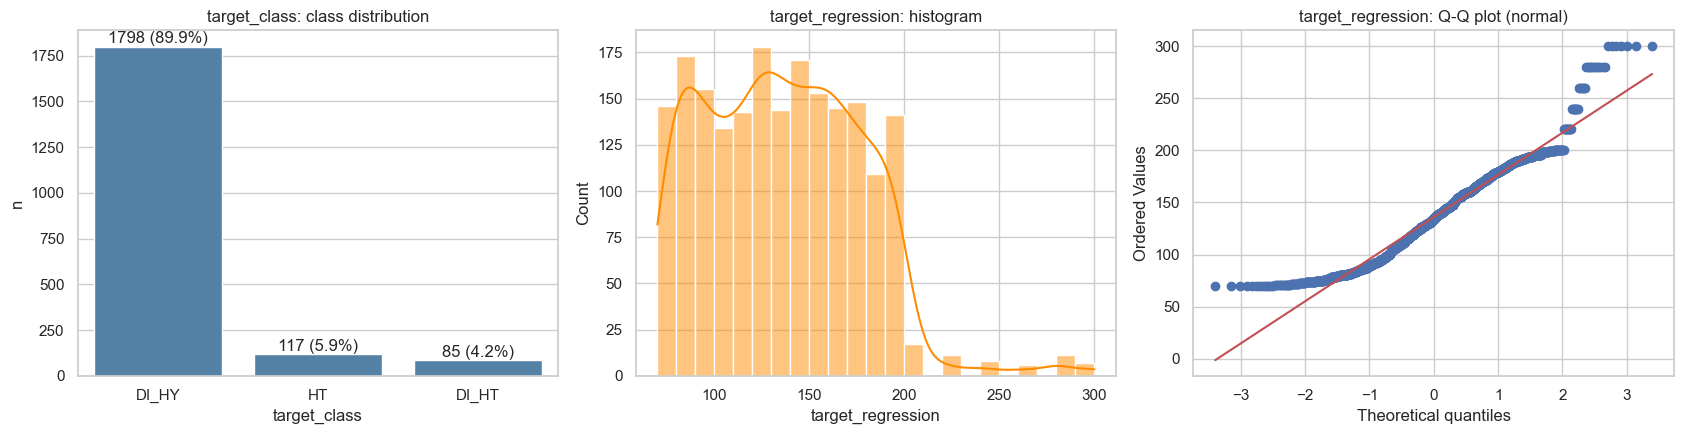

Imbalance ratio (majority / minority): 21.2
target_regression -> skew = 0.52, kurtosis = 0.42


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df[TARGET_CLS].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], color='steelblue')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f'{v} ({v/len(df):.1%})', ha='center')
axes[0].set_title('target_class: class distribution'); axes[0].set_ylabel('n')

sns.histplot(df[TARGET_REG], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('target_regression: histogram')

stats.probplot(df[TARGET_REG], dist='norm', plot=axes[2])
axes[2].set_title('target_regression: Q-Q plot (normal)')
plt.tight_layout(); plt.show()

print(f'Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f}')
print(f'target_regression -> skew = {df[TARGET_REG].skew():.2f}, '
      f'kurtosis = {df[TARGET_REG].kurt():.2f}')

**Conclusions:**

- **`target_class` is heavily imbalanced**: `DI_HY` accounts for about 90% of the records, against
  roughly 6% for `HT` and 4% for `DI_HT`. A classifier that always predicts `DI_HY` would already
  reach about 90% *accuracy*. For this reason, in classification we should use metrics such as **macro
  F1, *balanced accuracy*, per-class recall and the confusion matrix**, with **stratification** in the
  resampling methods and, possibly, `class_weight='balanced'`.
- **`target_regression`** ranges between 70 and 300 and shows a slight positive skew (right tail).

### 2.2 Numeric features: histograms and boxplots

The **histograms** show the shape of each distribution: whether it is symmetric or skewed, whether it
has one or several peaks, and whether it is approximately uniform or concentrated. The ***boxplots***
show the same information from another angle, the median, the quartiles and the distant values, and
allow the dispersion of different variables to be compared.

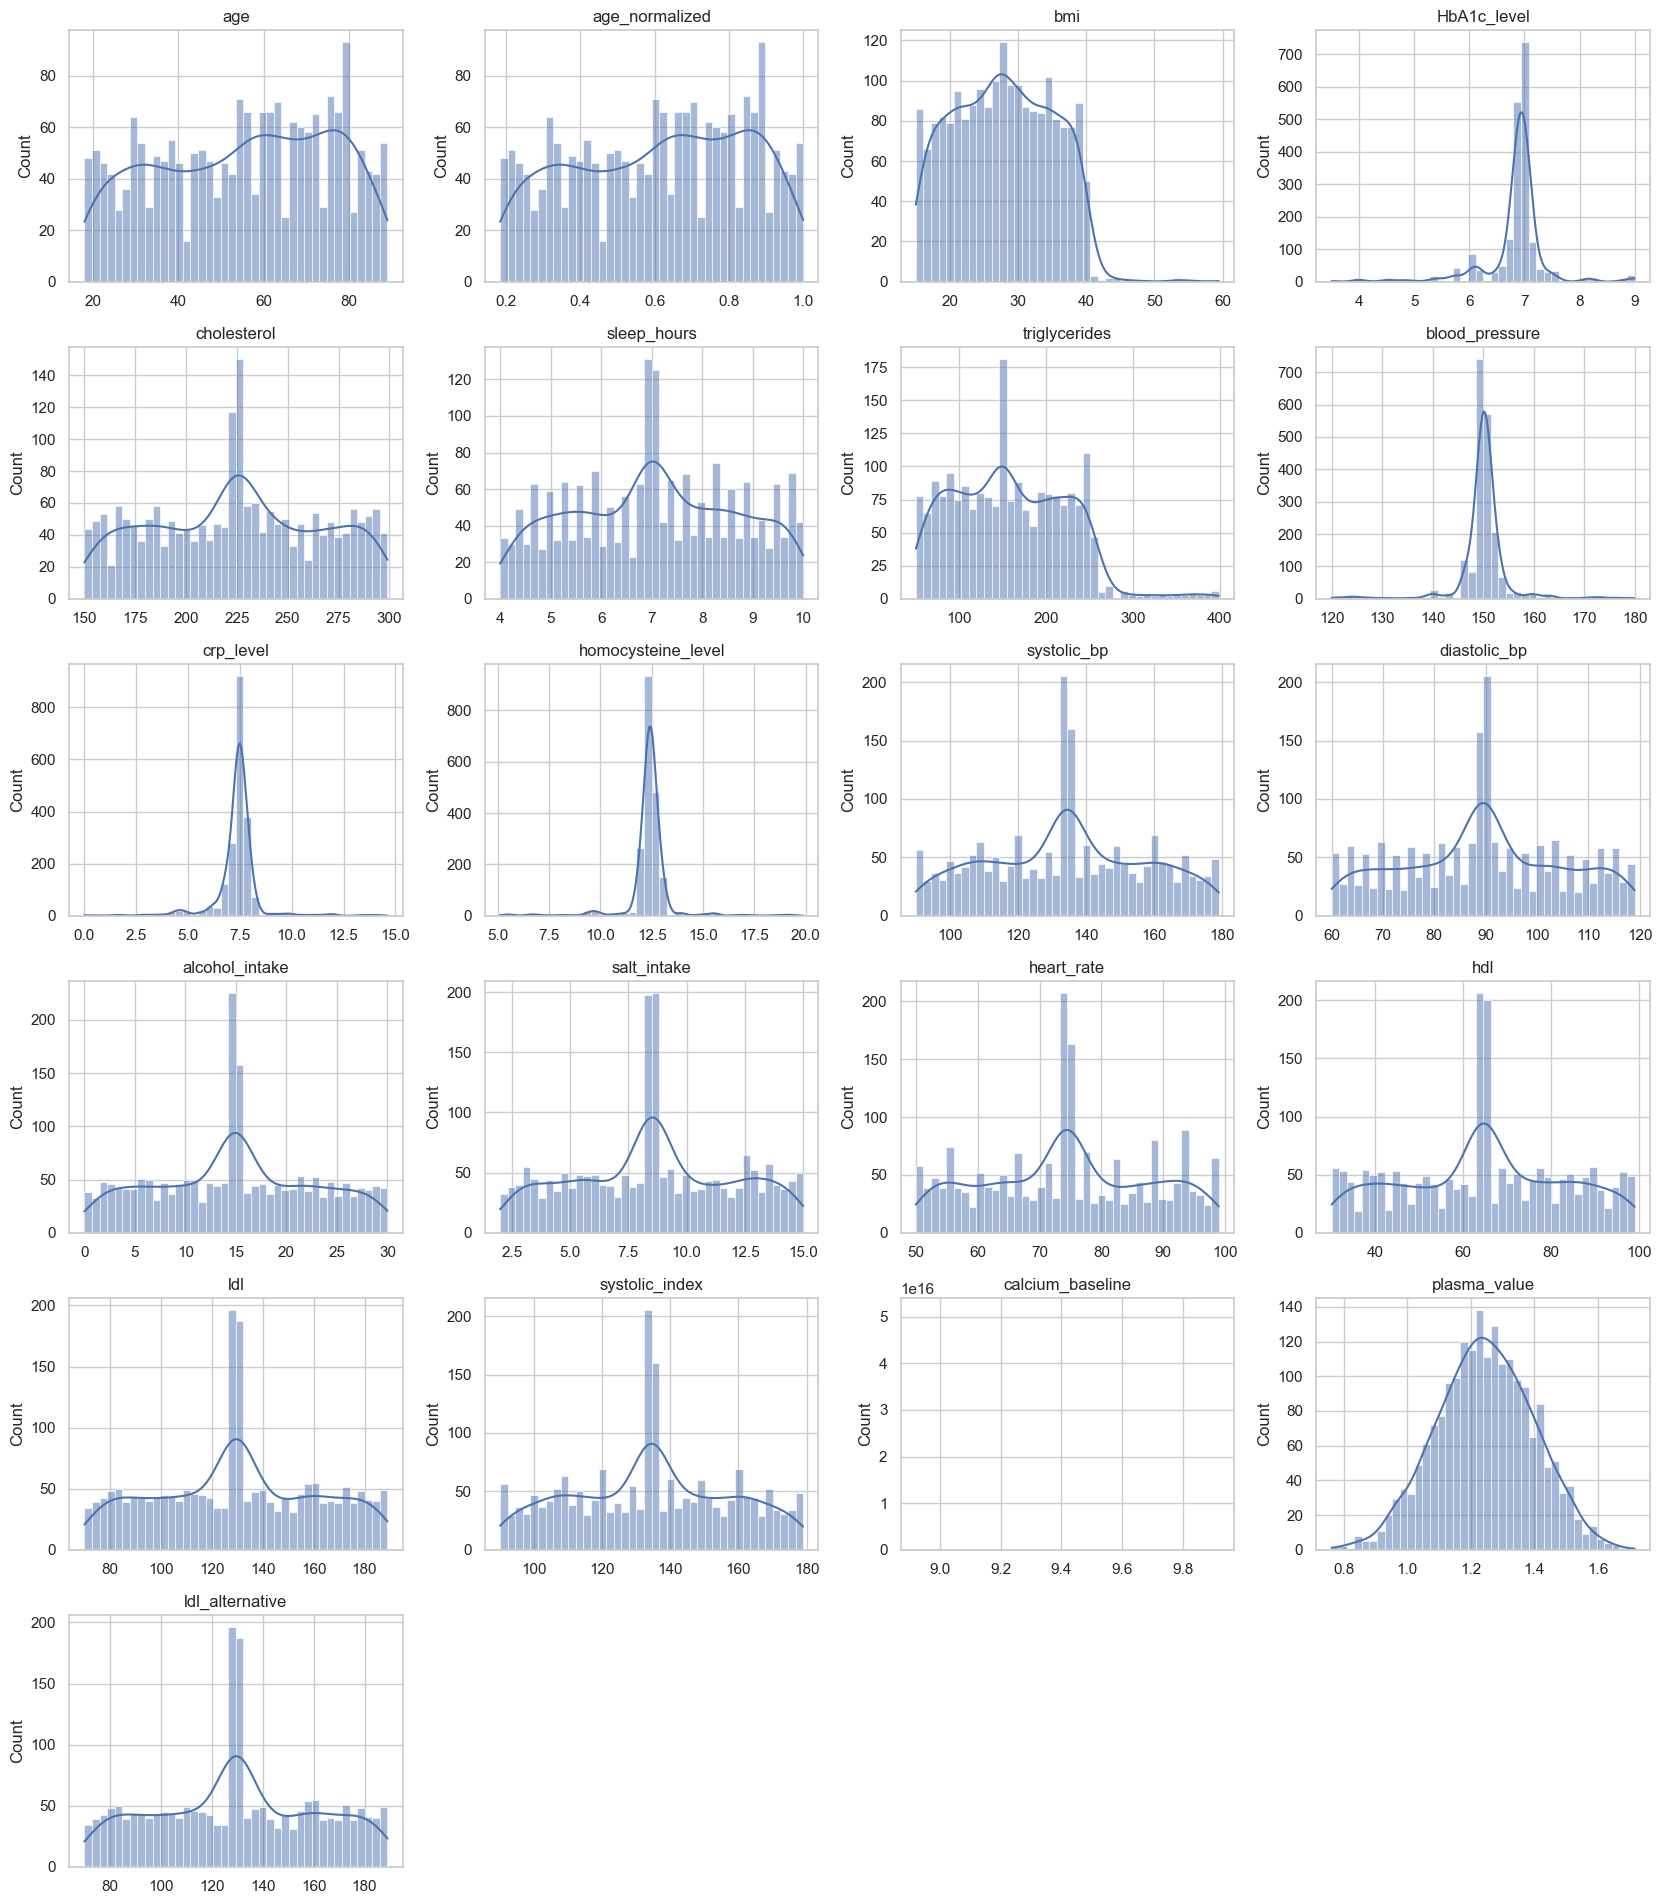

In [7]:
def grid_plot(cols, kind, ncols=4, size=(4.2, 3.2)):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows))
    axes = axes.ravel()
    for ax, c in zip(axes, cols):
        if kind == 'hist':
            sns.histplot(df[c], kde=True, ax=ax, bins=40)
        else:
            sns.boxplot(x=df[c], ax=ax, color='lightsteelblue')
        ax.set_title(c); ax.set_xlabel('')
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

grid_plot(num_cols, 'hist')

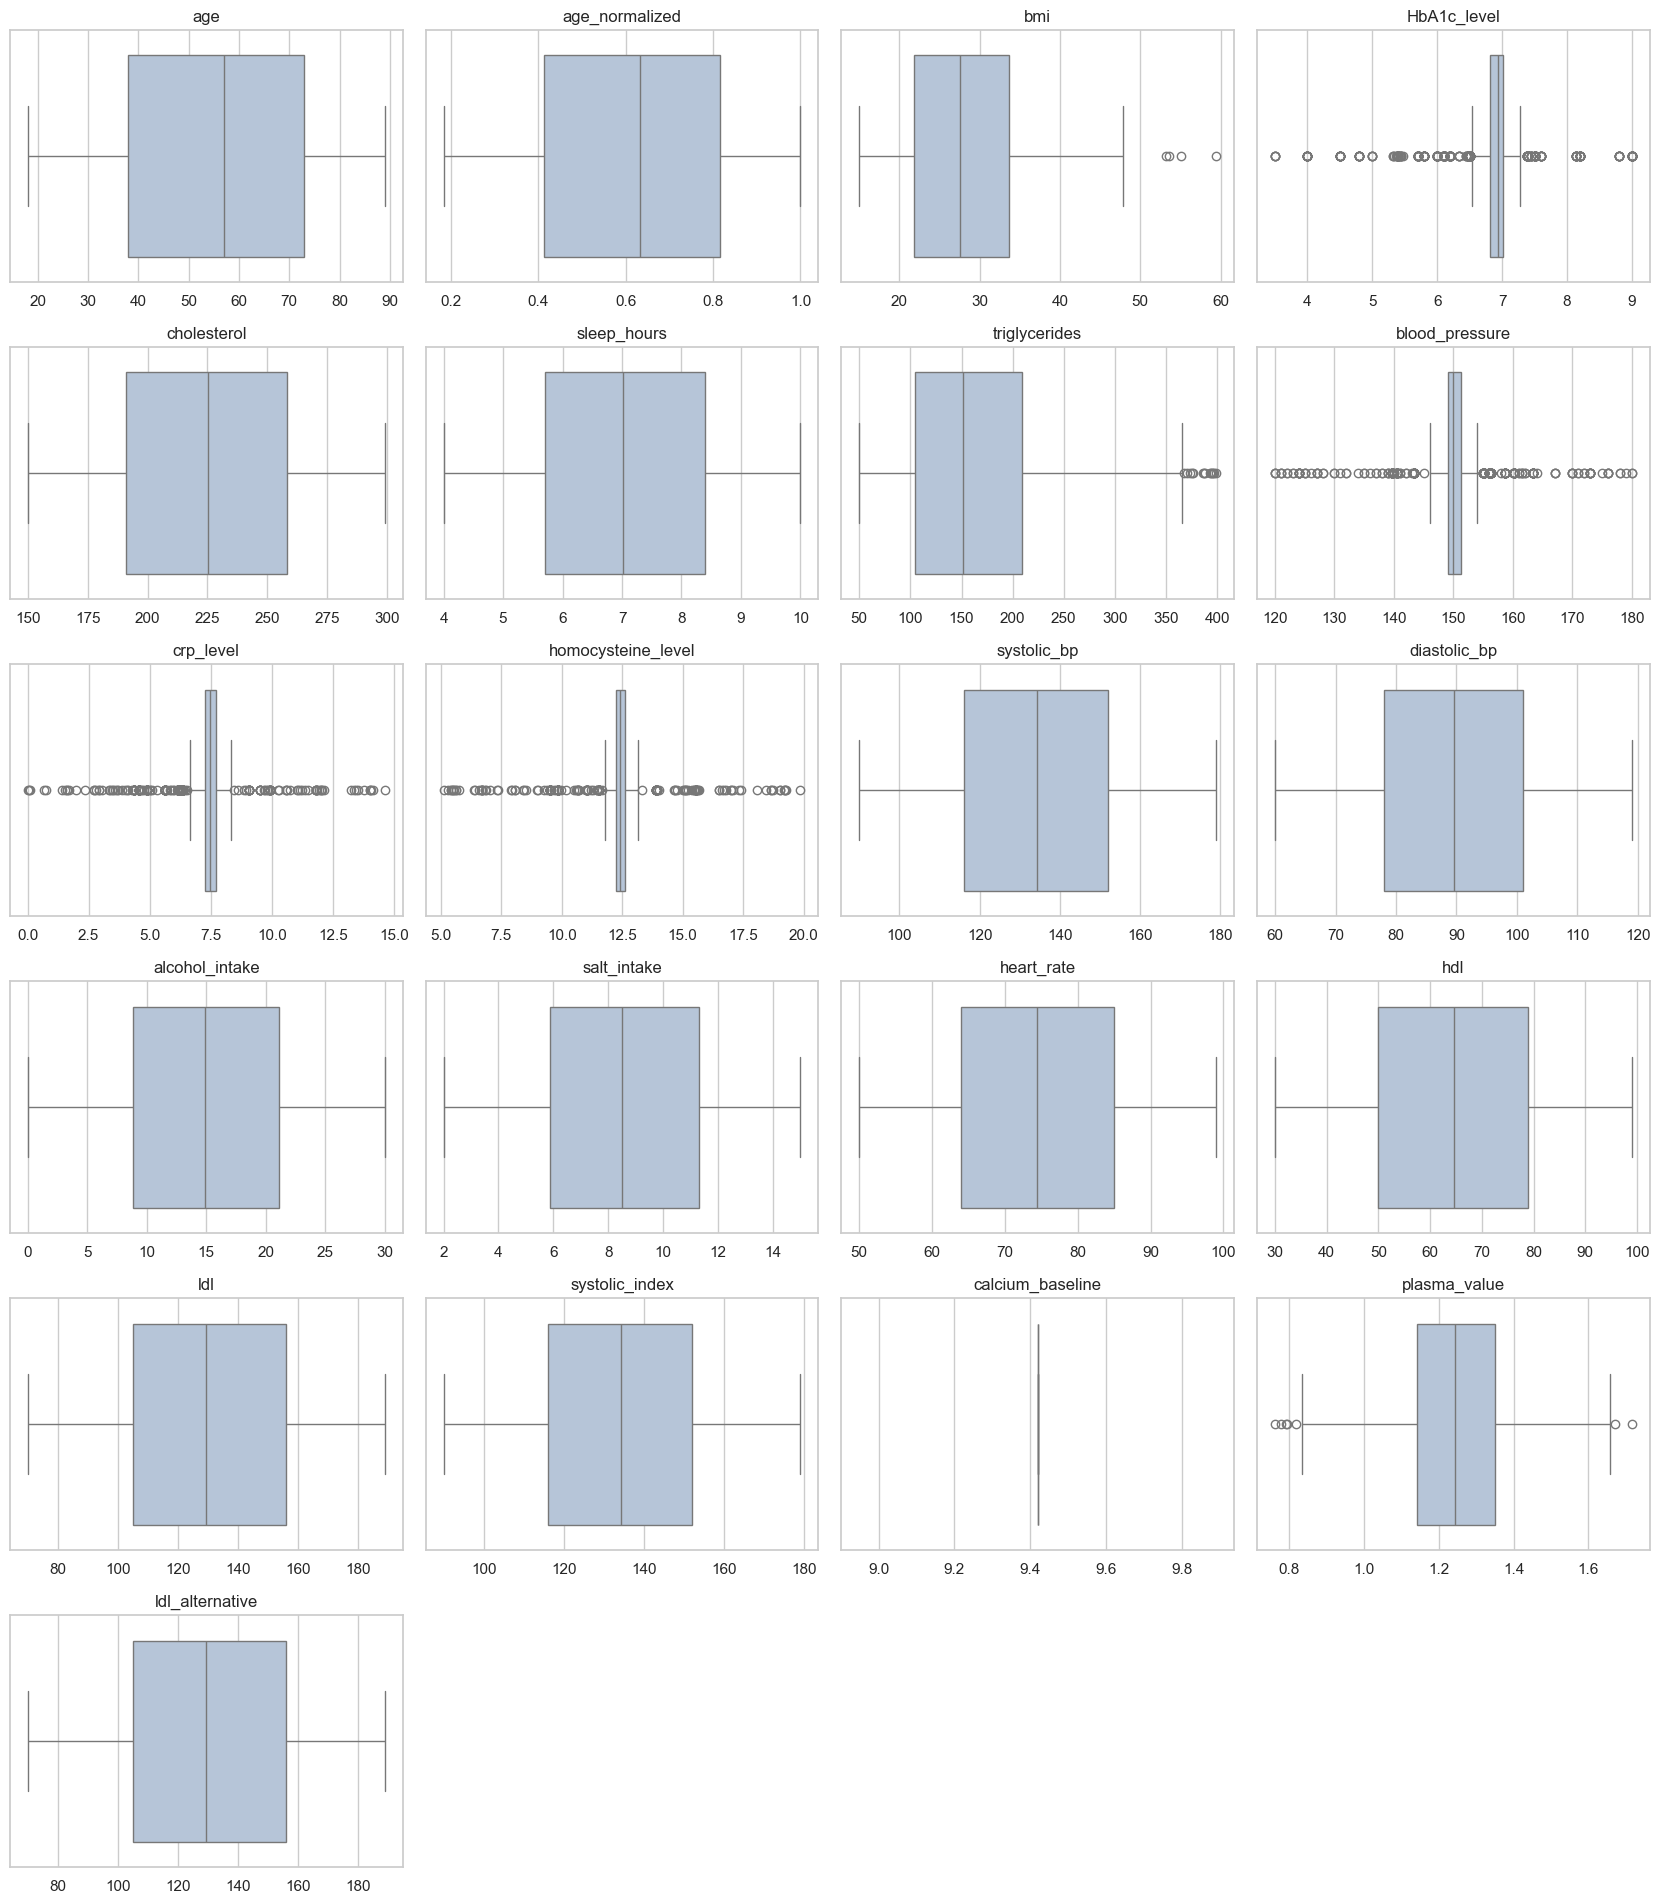

In [8]:
grid_plot(num_cols, 'box')

**Conclusions:** the distributions fall into four distinct patterns:

- **Approximately uniform**: `age`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`,
  `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` and `ldl`. These are almost "flat"
  distributions, with similar frequencies across the whole range.
- **Highly concentrated, with long tails**: `HbA1c_level`, `blood_pressure`, `crp_level` and
  `homocysteine_level`. They confirm the high kurtosis observed in 1.3.
- **Positively skewed**: `bmi` and `triglycerides`.
- **Approximately normal**: `plasma_value`.
- **Constant**: `calcium_baseline`, which appears as a single bar.

### 2.3 Outlier detection

The interquartile range rule flags as an *outlier* any observation lying more than 1.5 × IQR below the
first quartile or above the third. It is the criterion implicit in the *boxplots* of the previous
section.

We apply it to every numeric variable in order to quantify the number of **outliers**.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

out = pd.DataFrame({'n_outliers': {c: iqr_outliers(df[c]) for c in num_cols + [TARGET_REG]}})
out['%'] = out['n_outliers'] / len(df) * 100
out.sort_values('n_outliers', ascending=False)

,n_outliers,%
HbA1c_level,372,18.600
crp_level,228,11.400
blood_pressure,212,10.600
homocysteine_level,170,8.500
target_regression,18,0.900
triglycerides,14,0.700
plasma_value,7,0.350
bmi,4,0.200
heart_rate,0,0.000
ldl_alternative,0,0.000


**Conclusions:**
The *outliers* are concentrated in the leptokurtic features. Because the IQR of these variables is very
narrow, the 1.5 × IQR rule flags as *outliers* many values that are clinically plausible (for example
an HbA1c of 5.4%). For that reason **we do not remove them automatically**. In section 3 we will see
that, in the case of `HbA1c_level`, these "extreme" values are associated with a specific class (`HT`)
and are informative.

### 2.4 Categorical features

The univariate analysis of the ***categorical features*** is developed in section 1.4.

## 3. Bivariate analysis

### 3.1 Correlation between numeric features

We now move on to studying **relationships between pairs of variables**. We start with the correlation
matrix between the numeric *features*, which serves two distinct purposes:

- **detecting redundancy** — pairs with a correlation close to 1 carry the same information;
- **anticipating collinearity problems** in multiple regression.

We compute both **Pearson** and **Spearman** correlations. We exclude `calcium_baseline`, whose
correlation is undefined because it has zero variance.

We include **both target variables** in the matrix. `target_regression` enters directly, since it is
continuous. `target_class` is categorical, so it enters as three binary indicators, one per class. The
correlation between a continuous variable and a binary indicator is the **point-biserial
correlation**, which is interpreted in the same way. The matrix therefore also shows how much each
*feature* relates to each of the targets, and the two targets to each other.

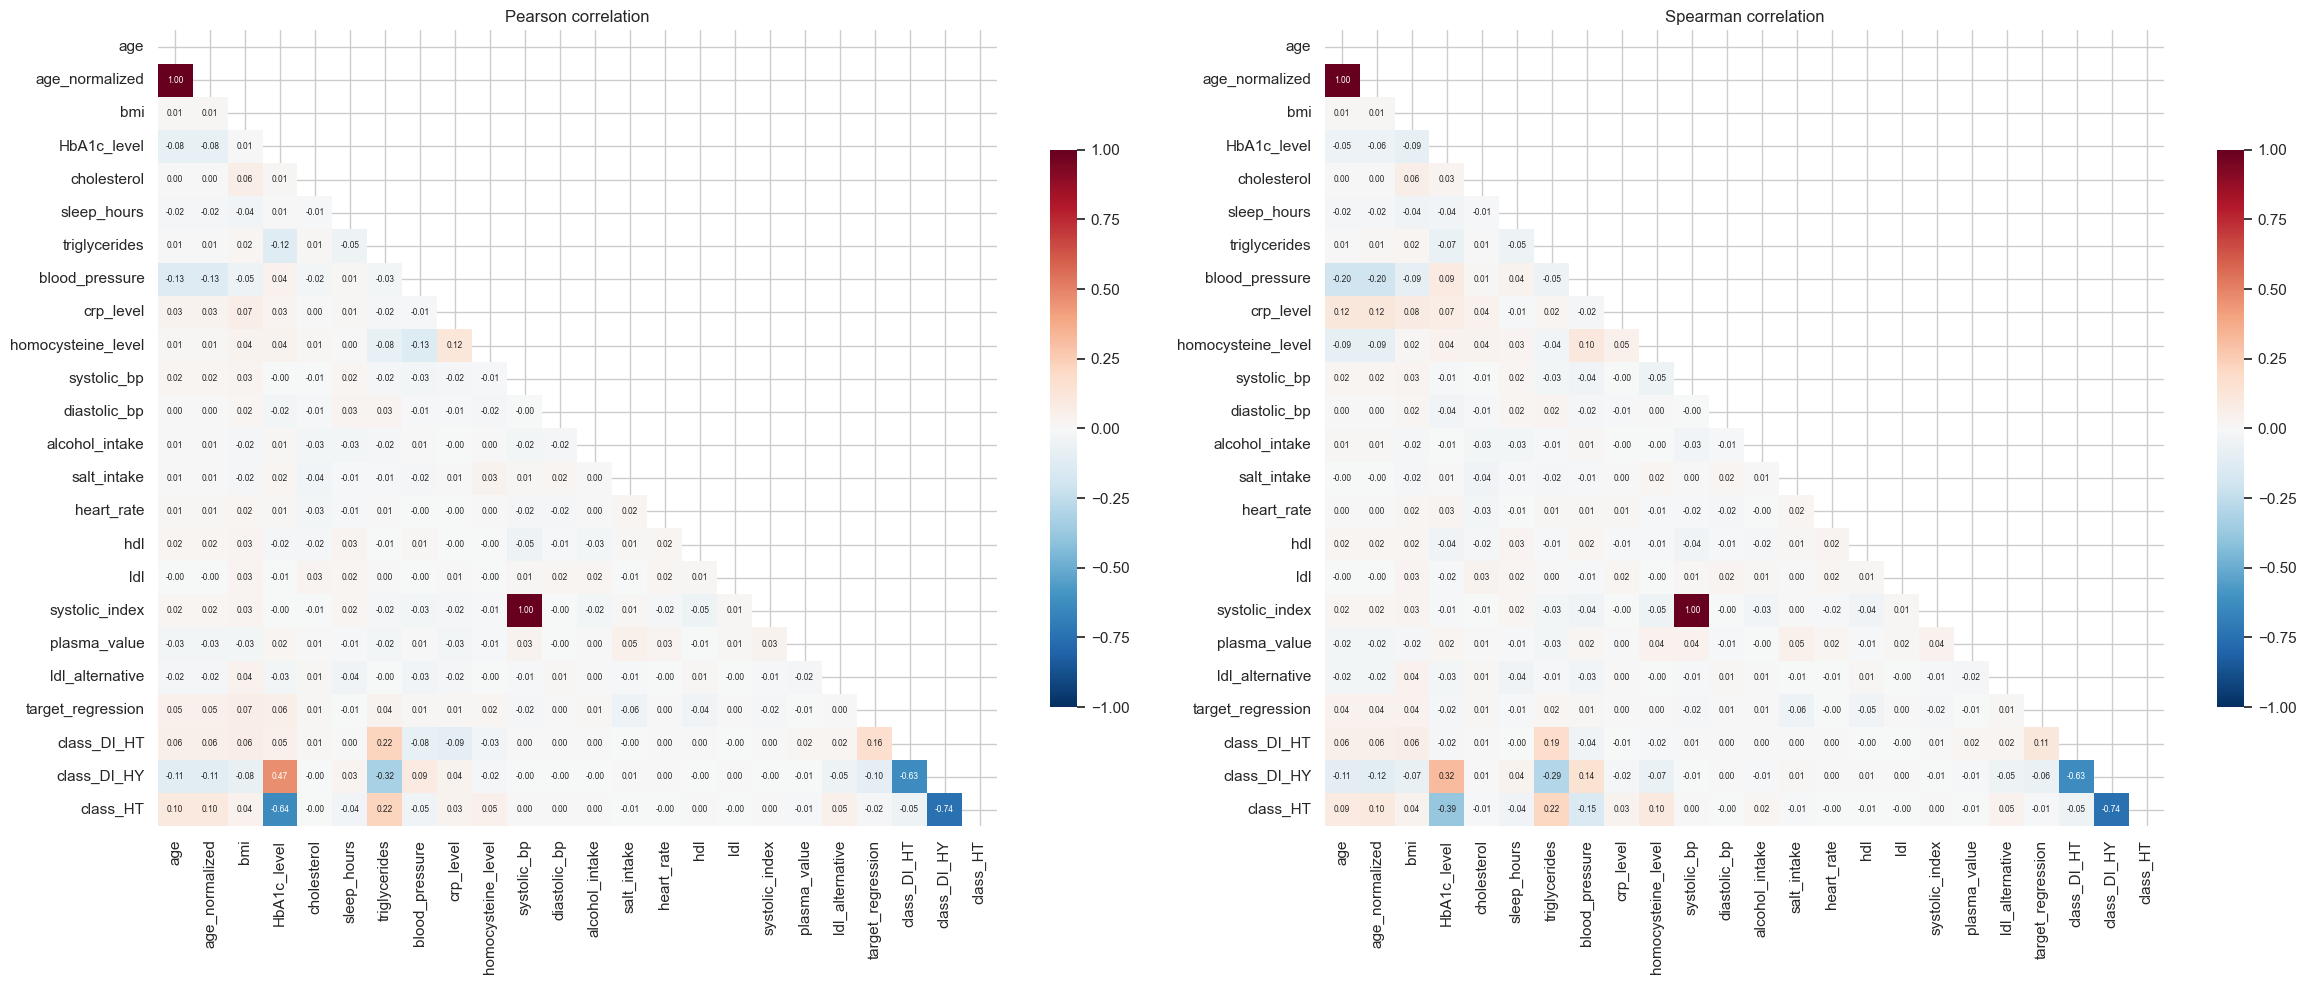

In [10]:
# Binary indicators of target_class, so that the relationship of each numeric
# variable with the classes can be read in the same matrix (point-biserial correlation)
class_indicators = pd.get_dummies(df[TARGET_CLS], prefix='class').astype(int)

corr_base = pd.concat([df[num_cols].drop(columns='calcium_baseline'),
                       df[[TARGET_REG]], class_indicators], axis=1)

corr_p = corr_base.corr(method='pearson')
corr_s = corr_base.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, m, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    sns.heatmap(m, mask=np.triu(np.ones_like(m, dtype=bool)), cmap='RdBu_r', vmin=-1, vmax=1,
                center=0, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax,
                cbar_kws={'shrink': .7})
    ax.set_title(f'{t} correlation')
plt.tight_layout(); plt.show()

In [11]:
upper = corr_p.where(np.triu(np.ones(corr_p.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > 0.3].sort_values(key=abs, ascending=False).to_frame('pearson')
high_pairs

,,pearson
systolic_bp,systolic_index,1.000
age,age_normalized,1.000
class_DI_HY,class_HT,-0.744
HbA1c_level,class_HT,-0.640
class_DI_HT,class_DI_HY,-0.629
HbA1c_level,class_DI_HY,0.466
triglycerides,class_DI_HY,-0.323


**Conclusions:** only **two pairs** of *features* show a high correlation, `age` with `age_normalized`
and `systolic_bp` with `systolic_index`, in both cases with a correlation equal or practically equal
to 1.

Outside these two pairs, **the correlations between *features* are practically null**, almost all of
them below 0.05 in absolute value.

As for the targets, the reading is quite asymmetric. No *feature* exceeds |r| = 0.07 with
`target_regression`, which anticipates how difficult the regression task will be. With the indicators
of `target_class`, on the other hand, clearly larger values appear, with `HbA1c_level` reaching
|r| = 0.64 and `triglycerides` 0.32, which indicates there is usable signal for classification.

The two targets show a moderate correlation with each other, with |r| = 0.16 between
`target_regression` and the indicator of class `DI_HT`. The relationship exists but is weak, and is
quantified appropriately in section 3.5.

### 3.2 Empirical confirmation of redundancy

The correlation matrix **suggests** redundancy, but does not prove it. Two variables can have a
correlation of 1 and not be the same column, and can have a correlation of 0 and still be related.
Before removing any *feature* we need to verify exactly **what kind of relationship** exists.

We test three hypotheses:
- whether `age_normalized` is a monotone transformation of `age`;
- whether `systolic_index` is an exact row-by-row copy of `systolic_bp`;
- and whether `ldl_alternative` contains the same values as `ldl` in a different order.

To close the section, we measure the joint effect of the redundancy on the data matrix.

In [12]:
print('--- age vs age_normalized ---')
print('  Spearman:', round(stats.spearmanr(df.age, df.age_normalized)[0], 6))
print('  Pearson :', round(df.age.corr(df.age_normalized), 6))
expected = (df.age - 2) / 87
print('  formula (age - 2) / 87 -> maximum residual:',
      f'{float((df.age_normalized - expected).abs().max()):.2e}')

print('\n--- systolic_bp vs systolic_index ---')
print('  equal on every row:', (df.systolic_bp == df.systolic_index).all())

print('\n--- ldl vs ldl_alternative ---')
print('  same set of values (sorted):',
      np.allclose(np.sort(df.ldl), np.sort(df.ldl_alternative)))
print('  rows where they match:', int(df.ldl.eq(df.ldl_alternative).sum()), 'of', len(df))
print('  Pearson correlation:', round(df.ldl.corr(df.ldl_alternative), 4))

--- age vs age_normalized ---
  Spearman: 0.999951
  Pearson : 1.0
  formula (age - 2) / 87 -> maximum residual: 9.89e-07

--- systolic_bp vs systolic_index ---
  equal on every row: True

--- ldl vs ldl_alternative ---
  same set of values (sorted): True
  rows where they match: 18 of 2000
  Pearson correlation: -0.0049


**Conclusions:**

- **`age_normalized` is a deterministic rescaling of `age`.** **It is redundant**: the two columns
  carry literally the same information, so it is enough to keep `age`.
- **`systolic_index` is an exact copy of `systolic_bp`**, equal on all 2000 rows. The vague definition
  in the assignment ("secondary index capturing haemodynamic pressure dynamics") corresponds to nothing
  new in the data. **It is redundant.**
- `ldl_alternative` has exactly the same set of values as `ldl`, but matches it on only 18 of the 2000
  rows, and the correlation between the two is practically null. This is consistent with a **random
  permutation of the rows of `ldl`**, meaning the column has the right distribution but each patient's
  value does not belong to them.

There is still a fourth check to make, of a different nature. The three above look at pairs of columns;
this one measures the **joint** effect of the redundancy on the data matrix.

We use two measures. The **condition number** of the standardized matrix grows as the columns become
linearly dependent, and serves as a global alarm. The **VIF**, or variance inflation factor, tells us,
for each variable, how many times the variance of its coefficient is inflated by collinearity with the
others, and is obtained from the diagonal of the inverse correlation matrix. A VIF of 1 means a
complete absence of collinearity.

In [13]:
def condition_number(data):
    """Condition number of the standardized matrix: grows with collinearity."""
    standardized = (data - data.mean()) / data.std()
    return float(np.linalg.cond(standardized.values))

def vif_of_columns(data):
    """VIF of each column, from the diagonal of the inverse correlation matrix."""
    R = np.corrcoef(data.values, rowvar=False)
    if np.linalg.matrix_rank(R) < R.shape[0]:
        return None          # there is an exact dependency, the inverse does not exist
    return pd.Series(np.diag(np.linalg.inv(R)), index=data.columns)

REDUNDANT = ['age_normalized', 'systolic_index', 'ldl_alternative']
num_without_constant = [c for c in num_cols if c != 'calcium_baseline']   # zero variance
before = df[num_without_constant]
after = df[[c for c in num_without_constant if c not in REDUNDANT]]

R_before = np.corrcoef(before.values, rowvar=False)
print(f'With the redundant columns ({before.shape[1]} variables):')
print(f'  rank of the correlation matrix: {np.linalg.matrix_rank(R_before)} of {before.shape[1]}')
print(f'  condition number: {condition_number(before):.3g}')
print(f'  VIF computable: {vif_of_columns(before) is not None}')

print('\nVIF of each suspect pair, computed pairwise:')
for a, b in [('age', 'age_normalized'), ('systolic_bp', 'systolic_index'),
             ('ldl', 'ldl_alternative')]:
    r = df[a].corr(df[b])
    print(f'  {a:12} vs {b:16} r = {r: .6f}  ->  VIF = {1 / (1 - r ** 2):.6g}')

print(f'\nWithout the redundant columns ({after.shape[1]} variables):')
print(f'  condition number: {condition_number(after):.3g}')
vif_after = vif_of_columns(after).sort_values(ascending=False)
print(f'  max VIF: {vif_after.max():.4f}'
      f'  |  all below 1.05: {bool((vif_after < 1.05).all())}')
vif_after.round(4).to_frame('VIF').T

With the redundant columns (20 variables):
  rank of the correlation matrix: 19 of 20
  condition number: 1.75e+15
  VIF computable: False

VIF of each suspect pair, computed pairwise:
  age          vs age_normalized   r =  1.000000  ->  VIF = 5.08766e+11
  systolic_bp  vs systolic_index   r =  1.000000  ->  VIF = 4.5036e+15
  ldl          vs ldl_alternative  r = -0.004942  ->  VIF = 1.00002

Without the redundant columns (17 variables):
  condition number: 1.29
  max VIF: 1.0441  |  all below 1.05: True


,homocysteine_level,blood_pressure,triglycerides,HbA1c_level,age,crp_level,bmi,cholesterol,sleep_hours,systolic_bp,plasma_value,hdl,salt_intake,alcohol_intake,diastolic_bp,heart_rate,ldl
VIF,1.044,1.041,1.027,1.026,1.025,1.023,1.019,1.010,1.008,1.008,1.008,1.007,1.007,1.005,1.005,1.004,1.004


**Conclusions:**

With the twenty original numeric columns, the correlation matrix has **rank 19 out of 20**. It is
missing a dimension, which means there is an **exact linear dependency** between columns. The matrix is
therefore not invertible and **the VIF cannot even be computed**. The condition number, 1.75e+15,
confirms the diagnosis: values above 30 are already considered problematic.

Computed pairwise, the suspect pairs separate clearly:

- `age` and `age_normalized`, with a VIF of the order of 1e+11;
- `systolic_bp` and `systolic_index`, with a VIF of the order of 1e+15, because they are exactly equal;
- `ldl` and `ldl_alternative`, with a **VIF of 1.00002**, that is, no collinearity at all.

This last result is important and deserves careful reading. **`ldl_alternative` is not removed because
of collinearity**, unlike the other two. Its problem is a different one and was demonstrated above: it
contains the values of `ldl` in another order, so the value appearing in each row does not belong to
that patient.

Once the three columns are removed, the picture changes completely. The condition number falls from
1.75e+15 to **1.29**, and **all the VIF values stay below 1.05**, with the maximum at 1.0441
(`homocysteine_level`). There is no multicollinearity whatsoever between the retained variables.

This has a practical consequence for part 5 of the assignment: the reason for being of **Ridge** is to
stabilize coefficients when the predictors are correlated, and here there is nothing to stabilize. It
is predictable that Ridge will bring no gain over an unregularized solution, and this is the evidence
that allows us to say so.

### 3.3 Consistency between derived features and their source variables

The assignment states that `age_level` and `bmi_level` are categories derived from `age` and `bmi`.
Judging by their names, `low_hdl_cholesterol` and `high_ldl_cholesterol` are *flags* built from `hdl`
and `ldl`.

It is worth checking whether that correspondence holds in the data. We compare each *flag* against the
usual clinical threshold (HDL < 40 and LDL ≥ 130) to assess how sharp it is.

We add a fifth panel that serves a different purpose. If `high_ldl_cholesterol` was built from the
patient's LDL values, then it must relate to `ldl`, but it has no reason to relate to
`ldl_alternative` if the latter is, as section 3.2 suggests, a random permutation of the rows.
Comparing the two panels side by side is a direct test of that hypothesis.

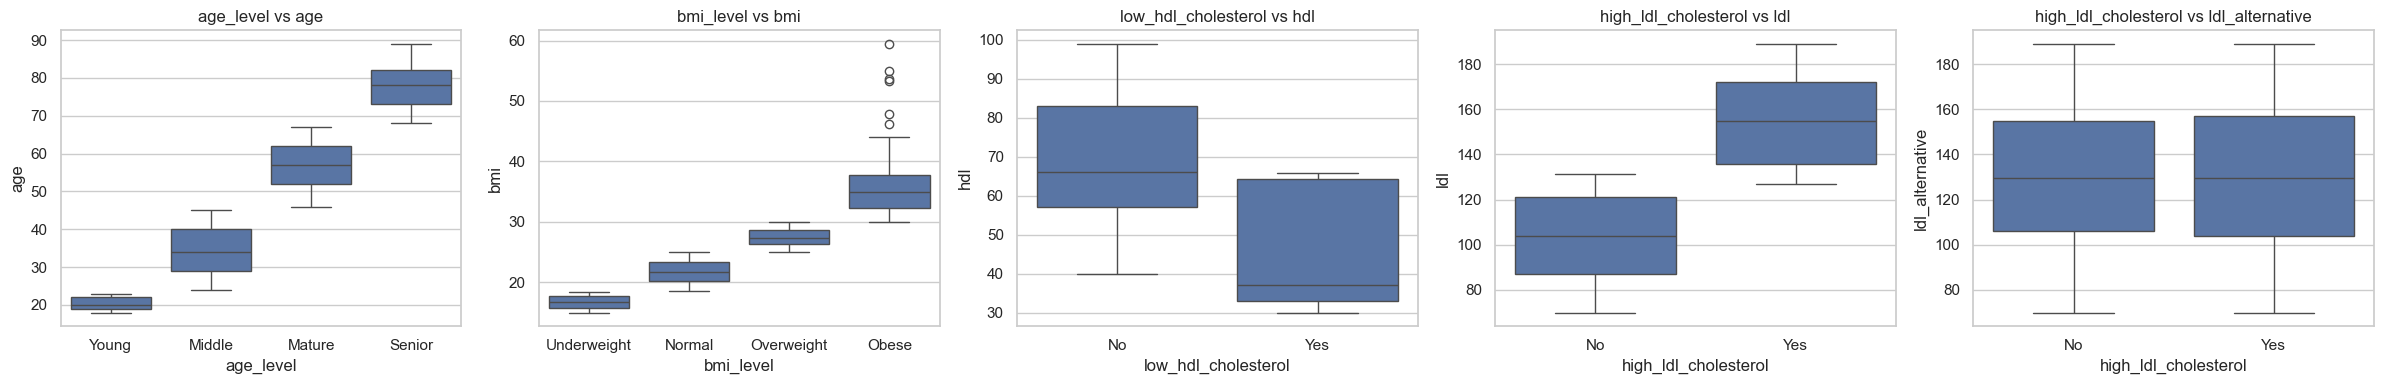

hdl < 40             False  True 
low_hdl_cholesterol              
No                    1647      0
Yes                    105    248

ldl >= 130            False  True 
high_ldl_cholesterol              
No                      940     38
Yes                     116    906

ldl_alternative >= 130  False  True 
high_ldl_cholesterol                
No                        521    457
Yes                       535    487

ldl              mean No= 103.56  Yes= 155.01

ldl_alternative  mean No= 129.73  Yes= 129.97


In [14]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
sns.boxplot(data=df, x='age_level', y='age',
            order=['Young','Middle','Mature','Senior'], ax=axes[0])
sns.boxplot(data=df, x='bmi_level', y='bmi',
            order=['Underweight','Normal','Overweight','Obese'], ax=axes[1])
sns.boxplot(data=df, x='low_hdl_cholesterol', y='hdl', ax=axes[2])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl', ax=axes[3])
sns.boxplot(data=df, x='high_ldl_cholesterol', y='ldl_alternative', ax=axes[4])
for ax in axes: ax.set_title(f'{ax.get_xlabel()} vs {ax.get_ylabel()}')
plt.tight_layout(); plt.show()

print(pd.crosstab(df.low_hdl_cholesterol, df.hdl < 40, colnames=['hdl < 40']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl >= 130, colnames=['ldl >= 130']))
print()
print(pd.crosstab(df.high_ldl_cholesterol, df.ldl_alternative >= 130,
                  colnames=['ldl_alternative >= 130']))

for column in ('ldl', 'ldl_alternative'):
    groups = [df.loc[df.high_ldl_cholesterol == k, column] for k in ('No', 'Yes')]
    print(f'\n{column:16s} mean No={groups[0].mean():7.2f}  Yes={groups[1].mean():7.2f}')

**Conclusions:** `age_level` and `bmi_level` correspond to **sharp discretizations** of `age` and
`bmi`.

In the variables `low_hdl_cholesterol` and `high_ldl_cholesterol` there is some overlap, that is, the
threshold is not perfectly sharp, but the association is strong. The contingency table confirms it: of
the 1022 records marked `Yes` in `high_ldl_cholesterol`, 906 do in fact have `ldl` equal to or above
130.

**The fifth panel is the most relevant result of this section.** While `ldl` clearly separates the two
levels of the *flag*, with means of 103.6 and 155.0, `ldl_alternative` **shows no relationship with it
at all**. Its means are 129.7 and 130.0, that is, the two distributions are indistinguishable.

This is the independent confirmation that `ldl_alternative` **does not belong to the patient**. Since
it shows no relationship, it is demonstrated that its values are disconnected from the record in which
they appear, which makes it a candidate for removal and not merely a suspicious variable.

In either case, the four derived variables are **partially redundant** with their source variables. In
a linear model, the usual practice is to keep the continuous variable, which preserves more
information than its binned version.

### 3.4 Numeric features vs `target_regression`

This analysis will guide us in choosing the predictor for the simple linear regression and the set of
predictors for the multiple one.

We compute two complementary measures, so as not to depend on a single one:

- the **Pearson correlation**, which measures the strength of the **linear** relationship, the one
  that linear regression models can actually exploit;
- the **Spearman correlation**, which measures monotone relationships even if curved, and which serves
  to rule out the hypothesis of a strong but non-linear relationship that the Pearson coefficient
  would be underestimating.

We add the **p-value** of the Pearson test, which tests the null hypothesis of no relationship (β₁ = 0).

In [15]:
# Working set: excludes the constant feature and the two redundant ones confirmed in 3.2
num_feats = [c for c in num_cols
             if c not in ('calcium_baseline', 'age_normalized', 'systolic_index')]

rel_reg = pd.DataFrame({
    'pearson': [df[c].corr(df[TARGET_REG]) for c in num_feats],
    'spearman': [df[c].corr(df[TARGET_REG], method='spearman') for c in num_feats],
    'p_value_pearson': [stats.pearsonr(df[c], df[TARGET_REG])[1] for c in num_feats],
}, index=num_feats)
rel_reg = rel_reg.sort_values('pearson', key=abs, ascending=False)
rel_reg

,pearson,spearman,p_value_pearson
bmi,0.070,0.044,0.002
salt_intake,-0.062,-0.062,0.005
HbA1c_level,0.055,-0.023,0.013
age,0.054,0.043,0.017
hdl,-0.040,-0.046,0.074
triglycerides,0.037,0.019,0.096
systolic_bp,-0.018,-0.016,0.426
homocysteine_level,0.016,0.002,0.474
blood_pressure,0.015,0.011,0.509
cholesterol,0.011,0.011,0.616


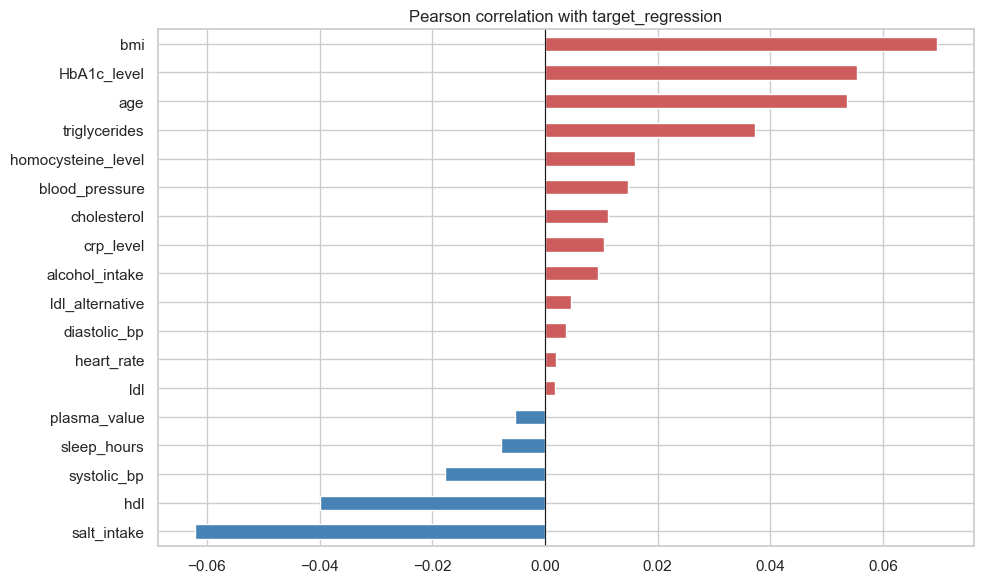

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
series = rel_reg['pearson'].sort_values()
series.plot.barh(ax=ax, color=np.where(series > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='k', lw=.8)
ax.set_title('Pearson correlation with target_regression')
plt.tight_layout(); plt.show()

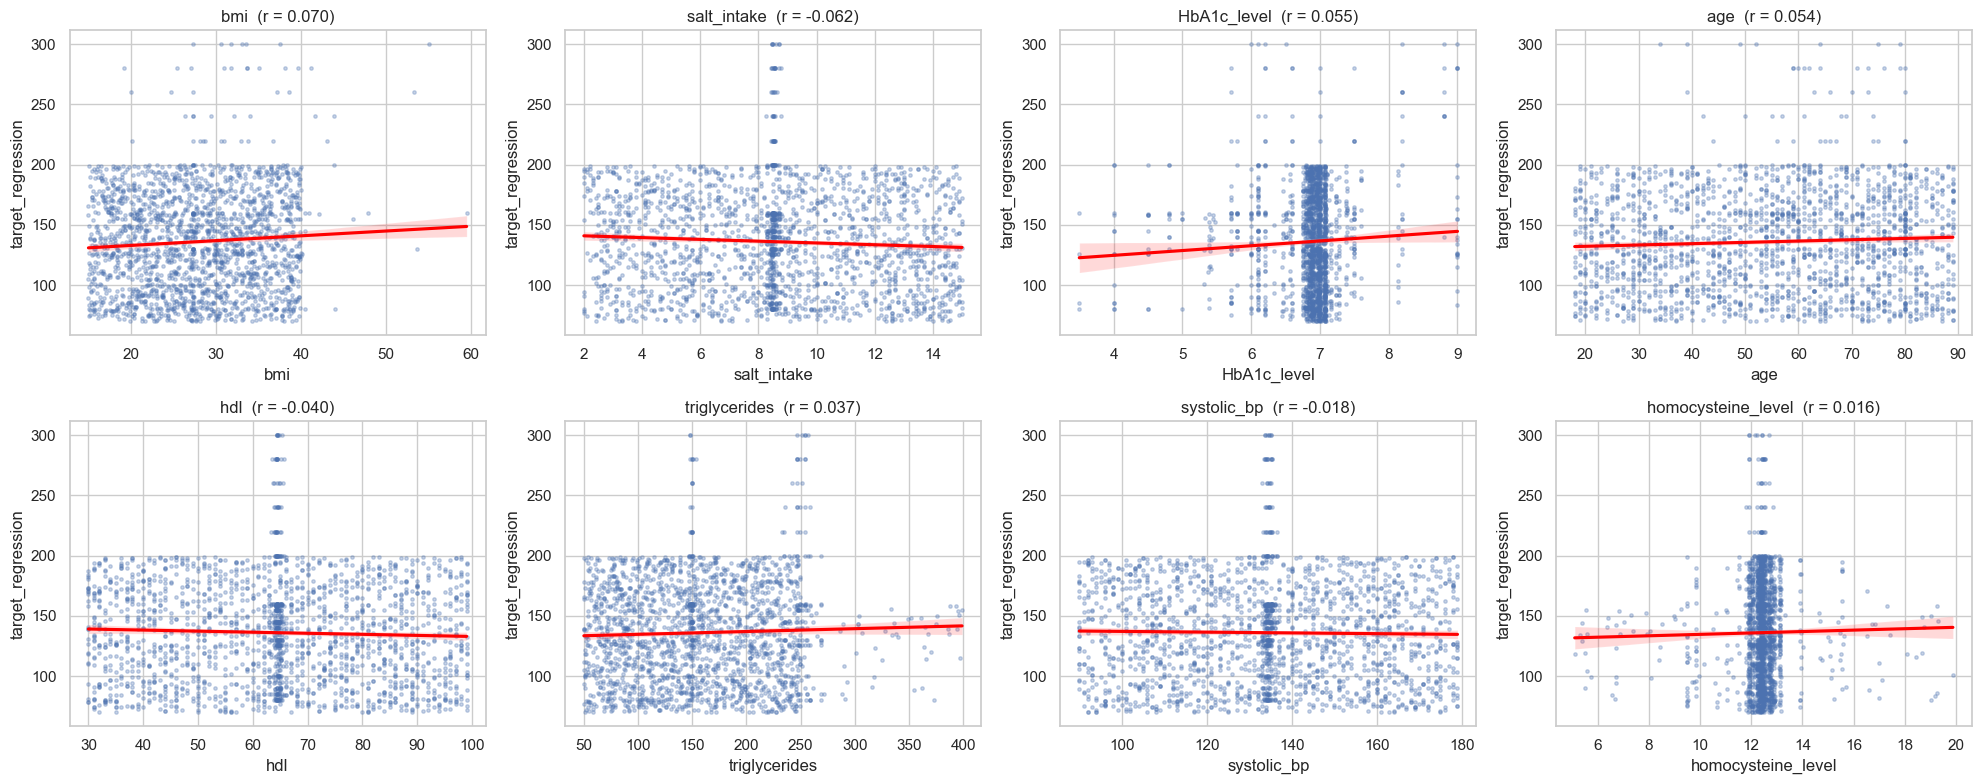

In [17]:
top = rel_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top):
    sns.regplot(data=df, x=c, y=TARGET_REG, ax=ax,
                scatter_kws={'s': 6, 'alpha': .3}, line_kws={'color': 'red'})
    ax.set_title(f'{c}  (r = {rel_reg.loc[c, "pearson"]:.3f})')
plt.tight_layout(); plt.show()

**Conclusions:**

**No numeric *feature* has a relevant linear relationship with `target_regression`.** The largest
absolute correlation is that of `bmi`, with r ≈ 0.070. It is followed by `salt_intake` (−0.062),
`HbA1c_level` (0.055) and `age` (0.054), which are statistically significant (p < 0.05) because of the
sample size (n = 2000). All the remaining ones are even closer to zero. In the fitted lines of the
scatter plots this is visible to the naked eye, the point clouds are practically horizontal.

The **Spearman correlations are very similar to the Pearson ones**, which rules out the hypothesis of a
strong but curved relationship that the Pearson coefficient was underestimating. The association is
genuinely weak, and not an artefact of how it was measured.

A **very low R²** is to be expected, both in simple and in multiple linear regression. The variable
with the largest effect on `target_regression` is, as we will see next, `target_class` itself. Since it
is the target of the other task, and not a target of this one, nothing prevents it from being used as a
predictor in the regression, and that is why we include it in these comparisons.

### 3.5 Categorical features vs `target_regression`

To assess the relationship between a categorical variable and a continuous one, we apply two tests:

- the **ANOVA** (F test), which is parametric and assumes normality and homogeneity of variances;
- the **Kruskal-Wallis**, which is the non-parametric alternative, based on ranks.

We also compute **η² (eta squared)**, which measures the **proportion of the variance** of
`target_regression` explained by each categorical variable. It is this effect-size measure, and not the
p-value, that tells us whether the variable is **practically** useful.

In [18]:
rows = []
for c in cat_cols + [TARGET_CLS]:
    groups = [g[TARGET_REG].values for _, g in df.groupby(c)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - df[TARGET_REG].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET_REG] - df[TARGET_REG].mean())**2).sum()
    rows.append({'feature': c, 'F_anova': F, 'p_anova': p_anova,
                 'p_kruskal': p_kw, 'eta2': eta2})
cat_reg = pd.DataFrame(rows).set_index('feature').sort_values('eta2', ascending=False)
cat_reg_show = cat_reg.copy()
for col in ['p_anova', 'p_kruskal']:
    cat_reg_show[col] = cat_reg_show[col].map('{:.3g}'.format)
cat_reg_show

,F_anova,p_anova,p_kruskal,eta2
feature,,,,
target_class,27.881,1.14e-12,5.31e-06,0.027
smoking,6.043,0.00242,0.00447,0.006
age_level,3.593,0.0131,0.0391,0.005
bmi_level,2.245,0.0812,0.33,0.003
physical_activity,3.068,0.0467,0.333,0.003
sugar_consumption,0.926,0.396,0.485,0.001
family_history,1.842,0.175,0.187,0.001
high_ldl_cholesterol,1.541,0.215,0.356,0.001
education_level,0.700,0.496,0.431,0.001


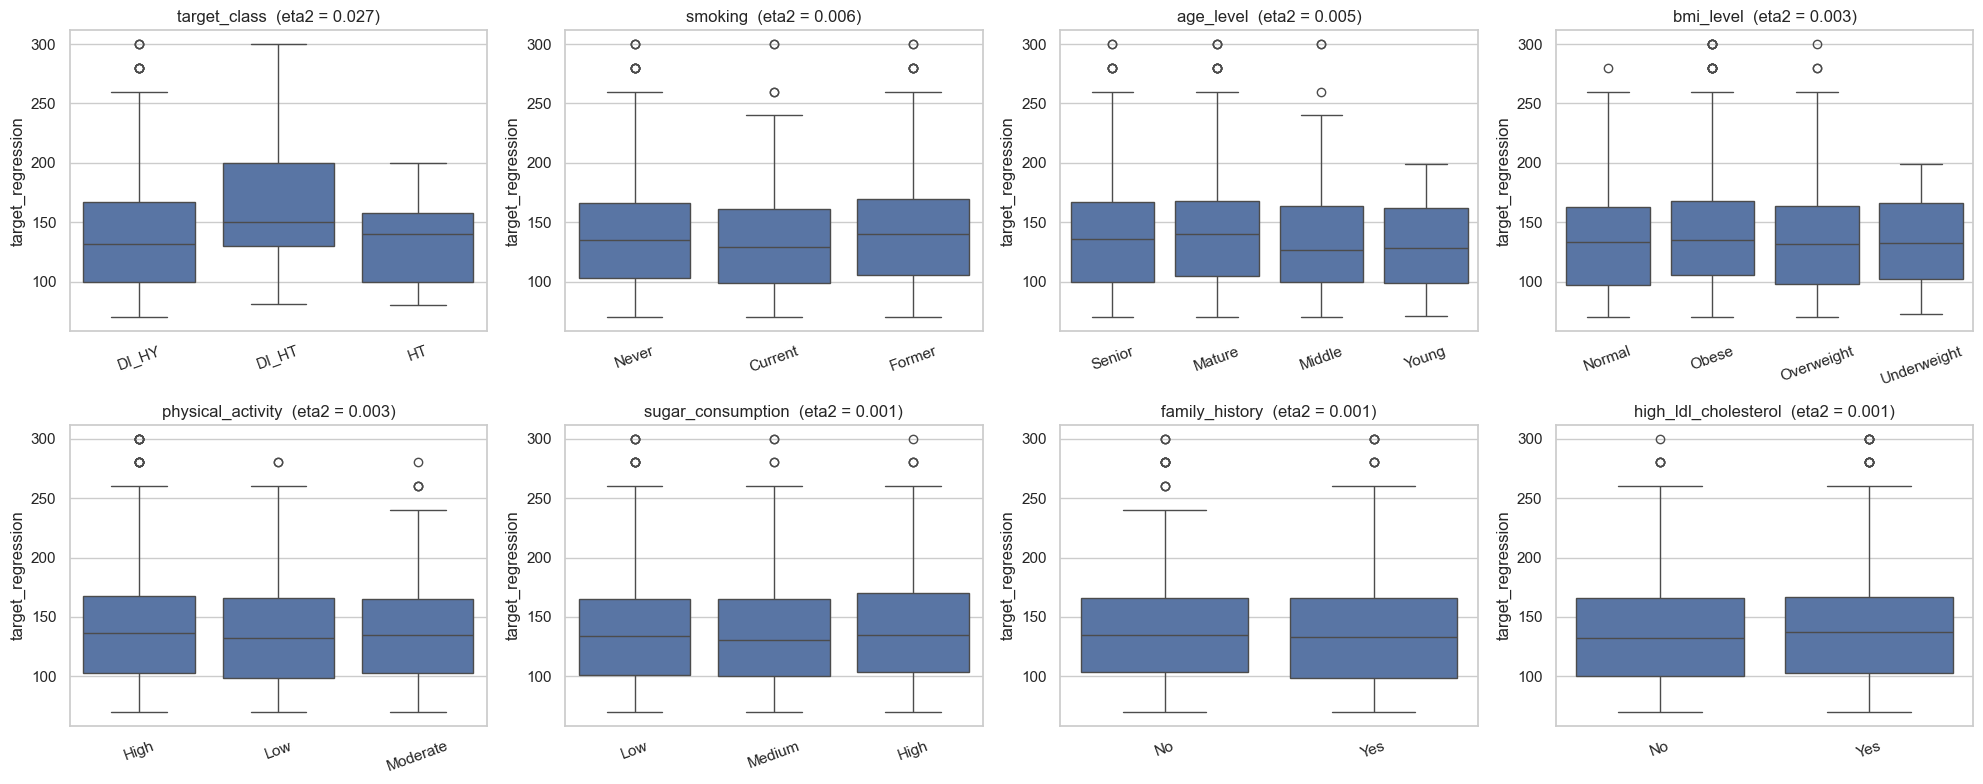

In [19]:
plot_cats = cat_reg.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, plot_cats):
    sns.boxplot(data=df, x=c, y=TARGET_REG, ax=ax)
    ax.set_title(f'{c}  (eta2 = {cat_reg.loc[c, "eta2"]:.3f})')
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Conclusions:** the categorical variable with the largest effect on `target_regression` is
**`target_class`** itself, with η² = 0.027 and p ≈ 1e-12 in the ANOVA. The effect is small, but it is
the largest of all, and, since it is the target of the other task and not a target of this one, it can
be used as a predictor in the regression. That is why we include it in this comparison.

All the remaining categorical variables have a **practically null η²** (≤ 0.006, with `smoking` as the
largest of them). Some do reach a p-value below 0.05, but without any practical relevance.

This confirms the diagnosis of the previous section: the available *features* explain practically
nothing of the variability of `target_regression`.

### 3.6 Numeric features vs `target_class`

We use the **Kruskal-Wallis test** to compare the distribution of each *feature* across the three
classes. We choose the non-parametric version because, as we have seen, the distributions are far from
normal and the classes have very different sizes.

We add **η²** as an effect-size measure, which indicates the proportion of the variance of each
*feature* explained by the class.

We also include `target_regression` in the list of variables tested. Being the target of the other task,
and not a target of this one, it can be used as a predictor in the classification, so it is of interest
to know how much the continuous target relates to the categorical one, symmetrically to what was done in
section 3.5.

In [20]:
classes = df[TARGET_CLS].value_counts().index.tolist()
rows = []
for c in num_feats + [TARGET_REG]:
    groups = [df.loc[df[TARGET_CLS] == k, c] for k in classes]
    H, p = stats.kruskal(*groups)
    ss_b = sum(len(g) * (g.mean() - df[c].mean())**2 for g in groups)
    eta2 = ss_b / ((df[c] - df[c].mean())**2).sum()
    rows.append({'feature': c, **{f'mean_{k}': g.mean() for k, g in zip(classes, groups)},
                 'kruskal_H': H, 'p_value': p, 'eta2': eta2})
num_cls = pd.DataFrame(rows).set_index('feature')
num_cls = num_cls.sort_values('eta2', ascending=False)
num_cls_show = num_cls.copy()
num_cls_show['p_value'] = num_cls_show['p_value'].map('{:.3g}'.format)
num_cls_show

,mean_DI_HY,mean_HT,mean_DI_HT,kruskal_H,p_value,eta2
feature,,,,,,
HbA1c_level,6.936,5.374,6.979,307.152,2.01e-67,0.410
triglycerides,151.159,217.040,227.074,170.839,7.99e-38,0.105
target_regression,134.676,132.812,168.190,24.290,5.31e-06,0.027
age,54.419,63.060,60.706,23.972,6.23e-06,0.013
crp_level,7.390,7.514,6.881,2.422,0.298,0.010
blood_pressure,150.299,149.190,148.195,48.963,2.33e-11,0.009
bmi,27.623,29.051,29.987,11.401,0.00334,0.006
homocysteine_level,12.373,12.606,12.194,20.806,3.03e-05,0.004
ldl_alternative,129.270,136.217,133.376,5.109,0.0777,0.003


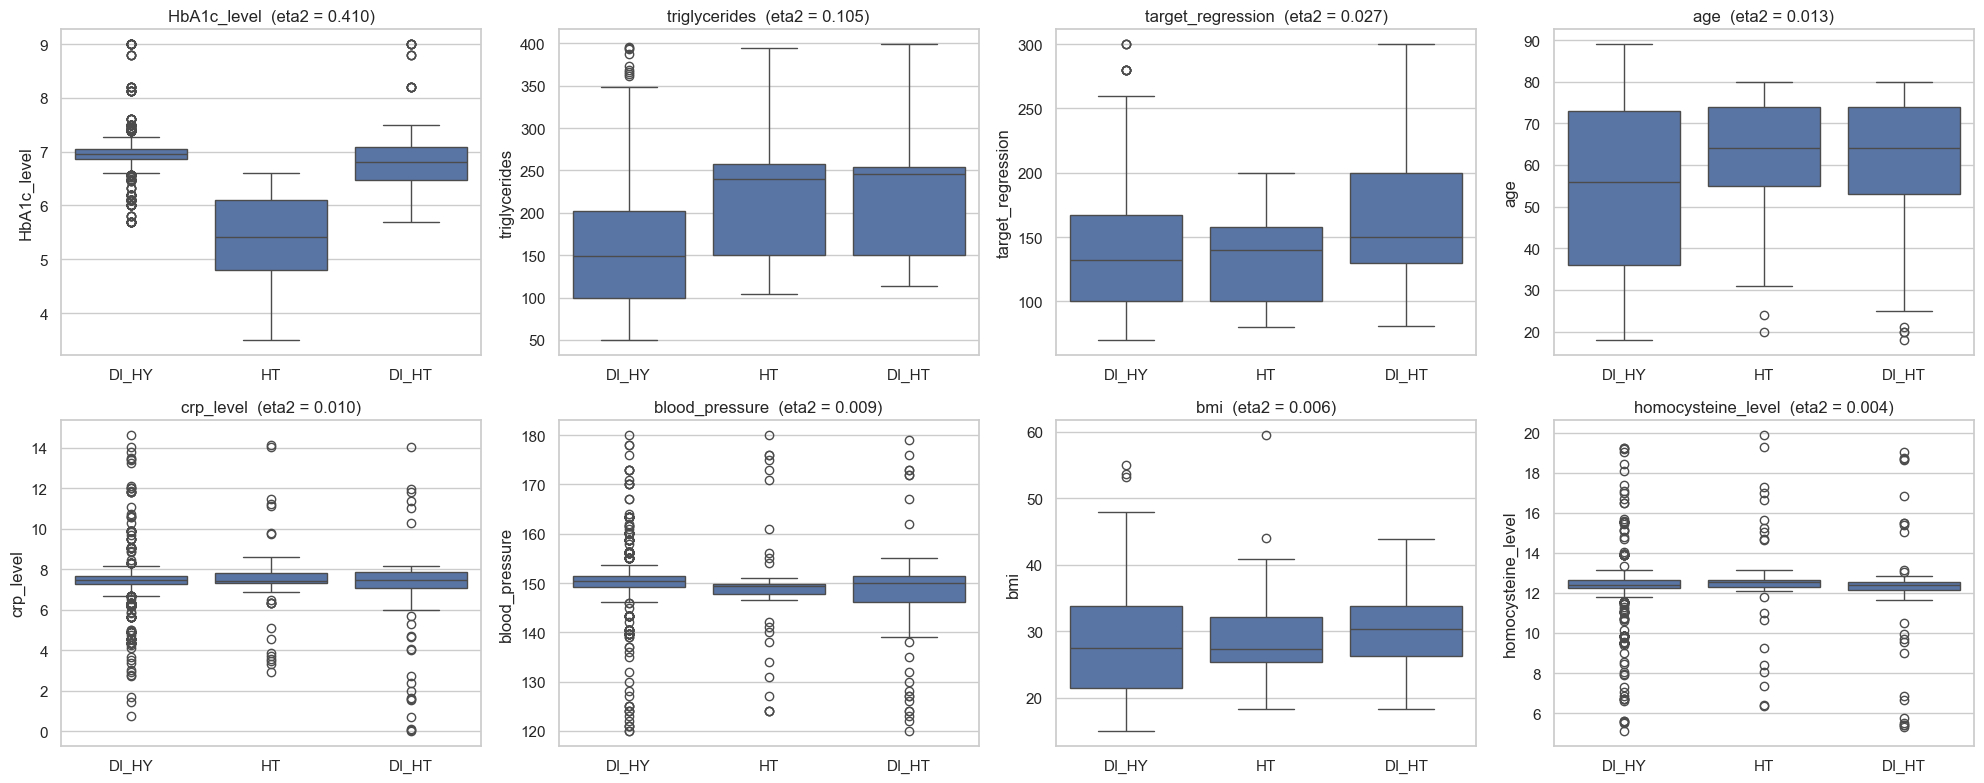

In [21]:
top_cls = num_cls.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, top_cls):
    sns.boxplot(data=df, x=TARGET_CLS, y=c, order=classes, ax=ax)
    ax.set_title(f'{c}  (eta2 = {num_cls.loc[c, "eta2"]:.3f})'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

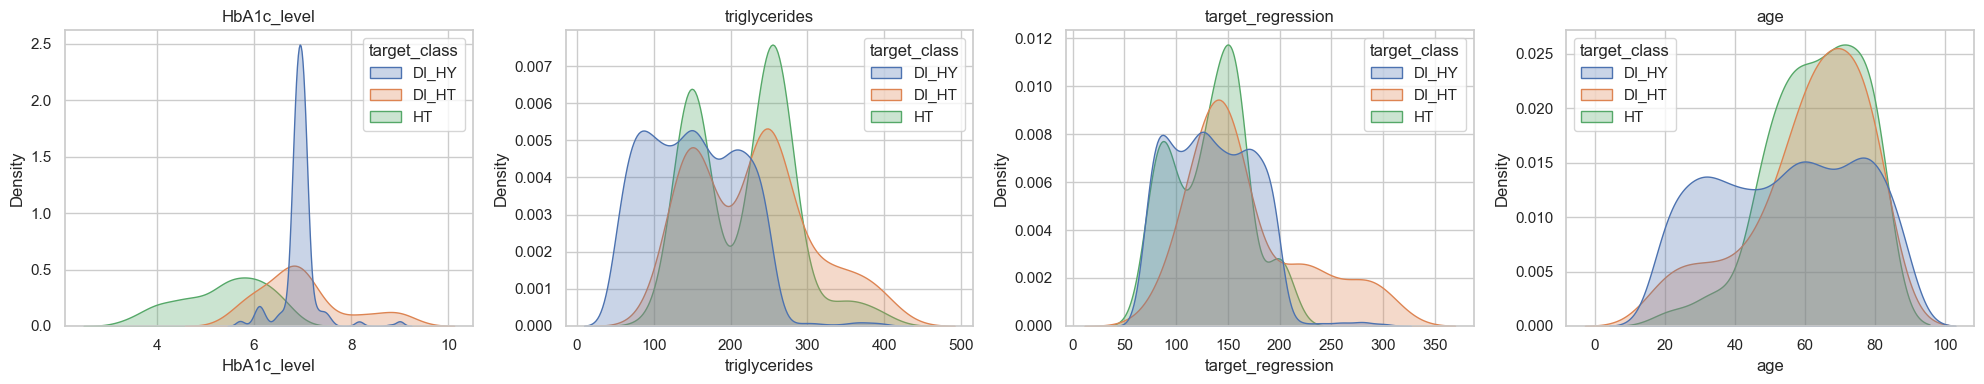

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, num_cls.index[:4]):
    sns.kdeplot(data=df, x=c, hue=TARGET_CLS, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Conclusions:**

Ordered by effect size, the following stand out:

- **`HbA1c_level` (η² = 0.41, Kruskal-Wallis H = 307, p ≈ 2e-67)** is the most discriminative
  *feature*, explaining about **41% of the variance** of its own distribution across classes. This
  makes clinical sense, because `HbA1c` is the marker of diabetes and `HT` is the only class without a
  diabetic component. It is the feature that best separates `HT` from the others.
- **`triglycerides` (η² = 0.105, p ≈ 8e-38)**: substantially higher values in `DI_HT` (≈ 227) and `HT`
  (≈ 217) than in `DI_HY` (≈ 151).
- With much smaller but still statistically detectable effects: `age` (η² = 0.013), `blood_pressure`
  (0.009), `bmi` (0.006) and `homocysteine_level` (0.004).
- **Only 6 of the 18 numeric *features*** show significant differences between classes. The remaining
  ones, including `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake` and
  `salt_intake`, have practically identical distributions across the three classes and are, from the
  point of view of their clinical value, **uninformative**.

- As for the continuous target variable, `target_regression` shows η² = 0.027, with p ≈ 5e-06. The
  relationship between the two targets is real but modest, and coincides with the value obtained in
  section 3.5, as would be expected since it is the same association measured from the other side.

### 3.7 Categorical features vs `target_class` (χ² and Cramér's V)

To measure the association between two categorical variables we use the **chi-squared test** on the
contingency table, which tests their independence.

The χ² has, however, a known limitation: its value grows with the sample size, so with n = 2000 almost
everything ends up being "significant". To measure the **strength** of the association we therefore use
**Cramér's V**, which normalizes the χ² to a value between 0 and 1 and is interpretable as an effect
size (values below 0.1 correspond to weak associations).

In [23]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), chi2, p

rows = []
for c in cat_cols:
    v, chi2, p = cramers_v(df[c], df[TARGET_CLS])
    rows.append({'feature': c, 'chi2': chi2, 'p_value': p, 'cramers_v': v})
cat_cls = pd.DataFrame(rows).set_index('feature').sort_values('cramers_v', ascending=False)
cat_cls_show = cat_cls.copy()
cat_cls_show['p_value'] = cat_cls_show['p_value'].map('{:.3g}'.format)
cat_cls_show

,chi2,p_value,cramers_v
feature,,,
low_hdl_cholesterol,31.042,1.82e-07,0.125
age_level,50.711,3.39e-09,0.113
bmi_level,46.506,2.35e-08,0.108
physical_activity,19.793,0.000549,0.070
education_level,15.257,0.0042,0.062
sugar_consumption,13.796,0.00797,0.059
employment_status,13.748,0.00814,0.059
smoking,13.380,0.00956,0.058
family_history,6.147,0.0462,0.055


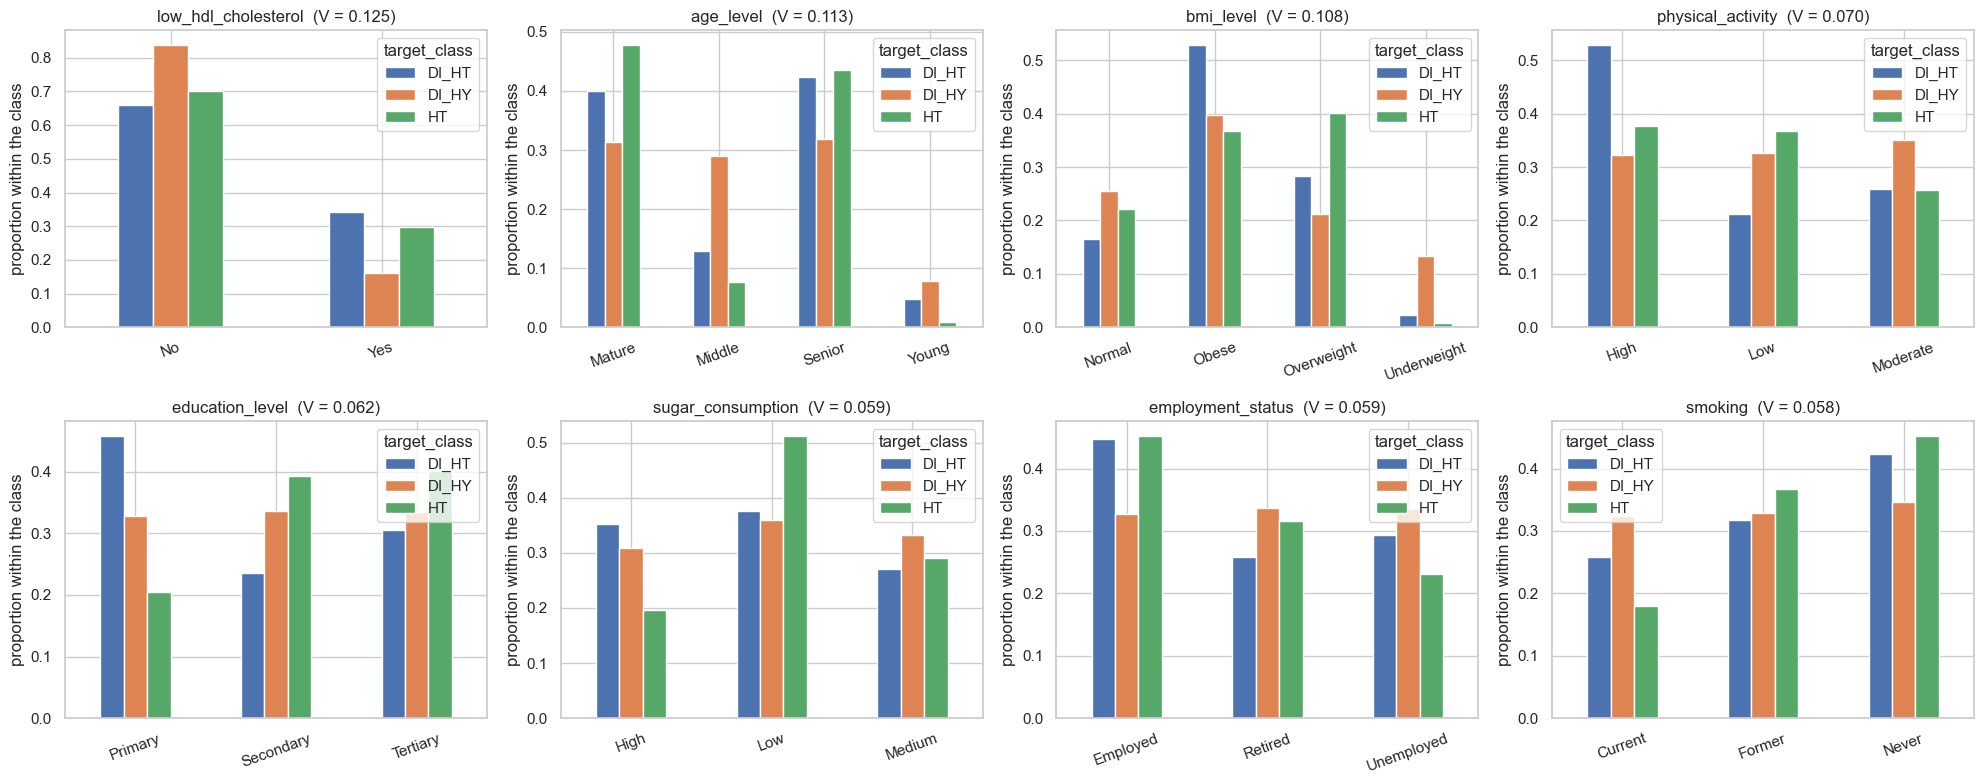

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8)); axes = axes.ravel()
for ax, c in zip(axes, cat_cls.index[:8]):
    ct = pd.crosstab(df[c], df[TARGET_CLS], normalize='columns')   # profile of each class
    ct.plot.bar(ax=ax, rot=20)
    ax.set_title(f'{c}  (V = {cat_cls.loc[c, "cramers_v"]:.3f})')
    ax.set_xlabel(''); ax.set_ylabel('proportion within the class')
plt.tight_layout(); plt.show()

**Conclusions:** the strongest associations are those of `low_hdl_cholesterol`, `age_level` and
`bmi_level`, but **all of them are weak in absolute terms** (V = 0.125, 0.113 and 0.108 respectively).
`age_level` and `bmi_level` confirm the effect of `age` and `bmi` already detected in 3.6.

**`low_hdl_cholesterol` is associated with the class even though `hdl` is not.** A *flag* derived from
a variable without signal should not, in principle, carry signal.

Several variables, `physical_activity`, `education_level`, `smoking` and `employment_status`, have a
p-value below 0.05 but V ≈ 0.06. The pattern already seen repeats itself: with n = 2000, tiny effects
become statistically significant without having any **practical relevance**.

Finally, **`gender` and `stress_level` show no association at all** with the class (p > 0.2). They are
the two clearest candidates for uninformative *features* among the categorical ones.

### 3.8 Relationship between the two targets and pairplot of the most relevant features

We close the bivariate analysis with a joint view of the most promising *features*. The *pairplot*
shows, in one go, the distribution of each variable by class (on the diagonal) and all the pairwise
relationships (off the diagonal), with the points coloured by class.

The goal is to understand whether any **combination** of *features* separates the classes better than
any of them on its own.

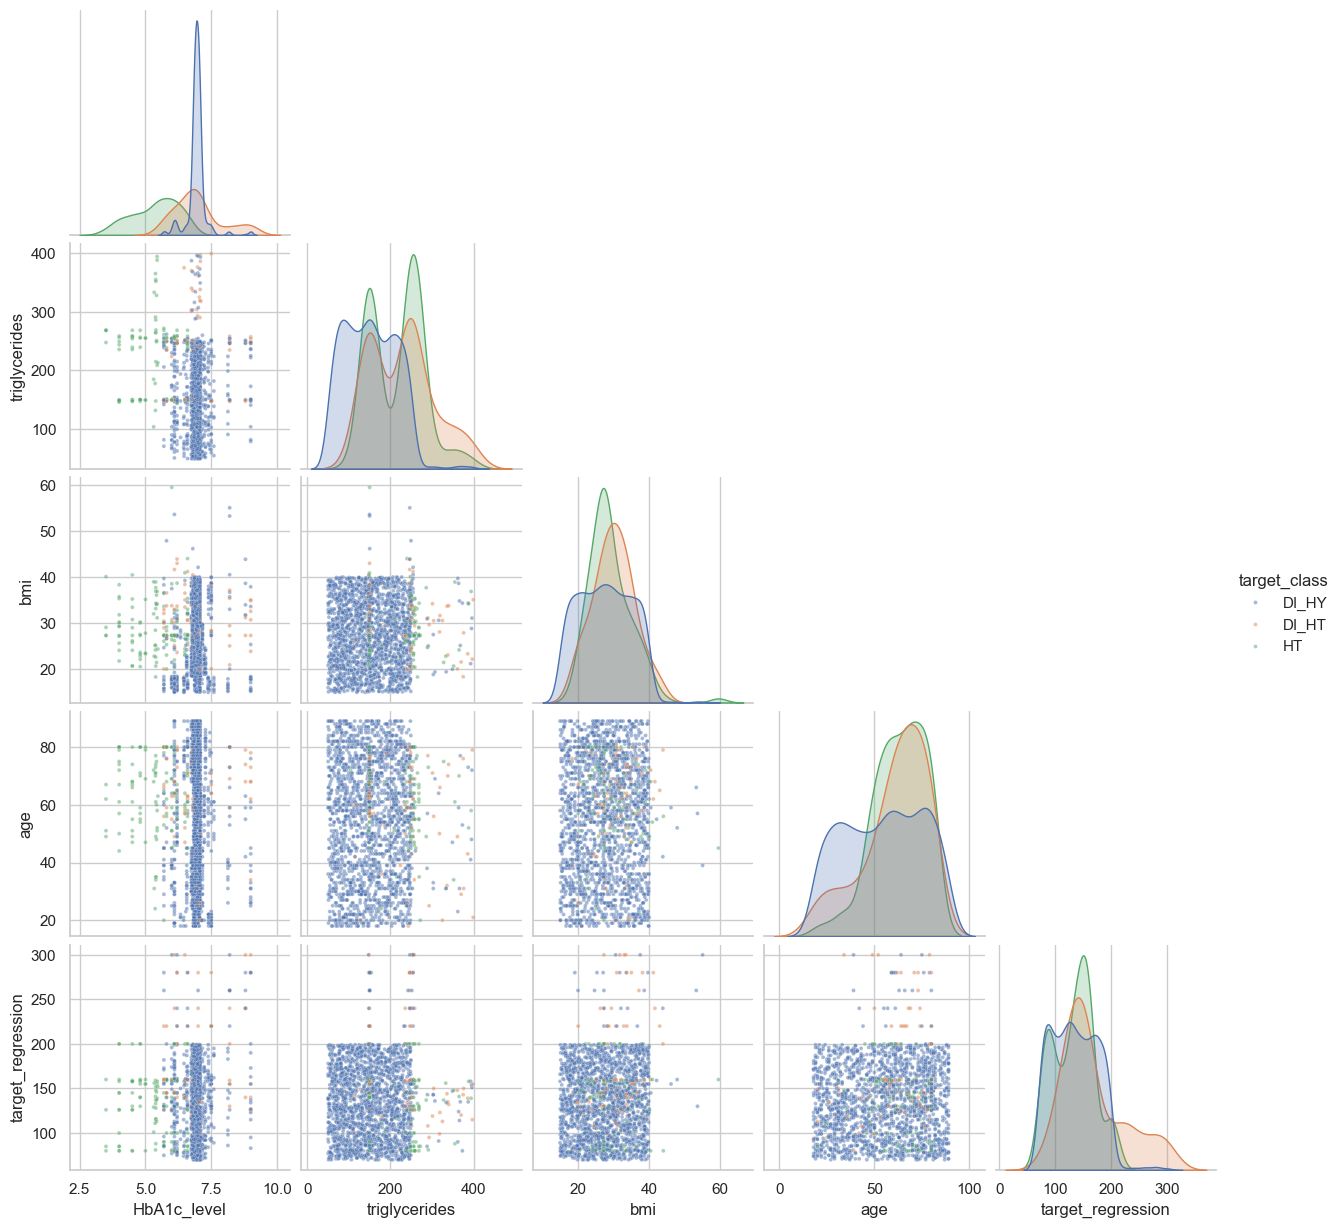

In [25]:
key = ['HbA1c_level', 'triglycerides', 'bmi', 'age', TARGET_REG]
sns.pairplot(df[key + [TARGET_CLS]], hue=TARGET_CLS, corner=True,
             plot_kws={'s': 8, 'alpha': .5}, diag_kws={'common_norm': False})
plt.show()

**Conclusions:** the *pairplot* confirms and enriches what we already knew, the *feature*
**`HbA1c_level` isolates class `HT` well**, forming a group clearly shifted to the left, and its
**combination with `triglycerides`** helps separate `DI_HT` and `HT` from `DI_HY`.

There remains, however, a **considerable overlap between `DI_HT` and `DI_HY`**. No combination of the
most relevant *features* distinguishes them sharply. It is predictable that this will be the hardest
distinction for the classifiers and the main source of error. Combining that with the fact that
`DI_HT` has only 85 records, it is to be expected that this will be the class with the worst *recall*.

### 3.9 Artefact detected: the decimal precision of the values depends on the class
Looking at the rows of the dataset, some values are "round" numbers (`hdl = 72.0`) and others have many
decimal places (`hdl = 64.3313679245283`), which suggests they were imputed or synthetically generated.
Let us check whether this is related to the class.

In [26]:
def not_rounded(s):
    return ((s * 10).round(6) % 1 != 0)

frac = pd.DataFrame({c: df.groupby(TARGET_CLS)[c].apply(lambda s: not_rounded(s).mean())
                     for c in num_feats}).T[classes]
frac.sort_values('DI_HY')

target_class,DI_HY,HT,DI_HT
age,0.000,0.000,0.000
cholesterol,0.031,0.812,0.671
triglycerides,0.031,0.812,0.671
bmi,0.049,0.923,0.953
systolic_bp,0.053,1.000,0.941
ldl,0.056,1.000,1.000
sleep_hours,0.056,1.000,1.000
hdl,0.056,1.000,1.000
heart_rate,0.056,1.000,1.000
salt_intake,0.056,1.000,1.000


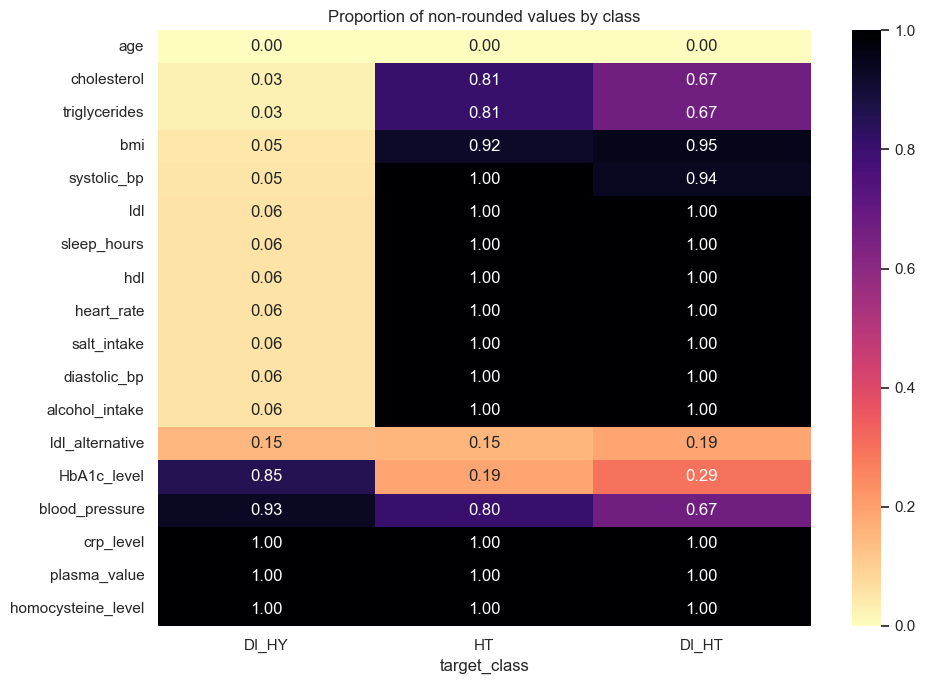

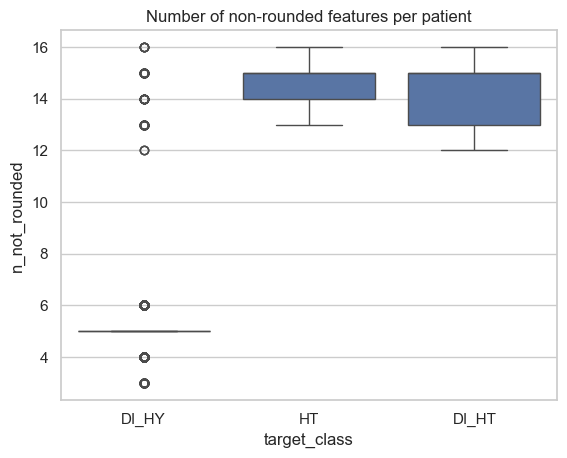

In [27]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(frac.sort_values('DI_HY'), annot=True, fmt='.2f', cmap='magma_r', ax=ax)
ax.set_title('Proportion of non-rounded values by class')
plt.tight_layout(); plt.show()

df_tmp = df.assign(n_not_rounded=sum(not_rounded(df[c]).astype(int) for c in num_feats))
sns.boxplot(data=df_tmp, x=TARGET_CLS, y='n_not_rounded', order=classes)
plt.title('Number of non-rounded features per patient'); plt.show()

**Conclusions:**

In the minority classes (`HT` and `DI_HT`), practically **100%** of the values of `hdl`, `heart_rate`,
`alcohol_intake`, `ldl`, `systolic_bp` and `bmi` have many decimal places. In the majority class
`DI_HY`, only about **5%** are in that situation. With `HbA1c_level` exactly the opposite happens.

This means that the records of the minority classes were **generated or imputed by a different
process** from the one used for the majority class.

**Implications, in order of importance:**

1. A flexible model can learn the class from the **"shape" of the number** rather than from its clinical value. This is *data leakage* and leads to optimistic performance that would not generalize to real data.
2. Linear models use the **value** of the variables and not their decimal representation, so they are little affected. Even so, **we should not create features derived from the precision**.
3. To assess relevance we use the Kruskal-Wallis tests with η², the χ² with Cramér's V and the correlations, which measure differences in the values of the variables and not in the way they are written.

## 4. Synthesis and preparation for the next stages

### 4.1 Summary table of the features

We gather in a single table the association measures computed throughout the bivariate analysis, in
order to back the decisions that follow with numbers.

In [28]:
summary = pd.DataFrame(index=num_feats + cat_cols)
summary['|r| target_reg'] = rel_reg['pearson'].abs()
summary['eta2 target_reg (cat)'] = cat_reg['eta2']
summary['eta2 target_class'] = num_cls['eta2']
summary['CramersV target_class'] = cat_cls['cramers_v']
summary['p target_class'] = num_cls['p_value'].combine_first(cat_cls['p_value'])
summary.sort_values('p target_class')

,|r| target_reg,eta2 target_reg (cat),eta2 target_class,CramersV target_class,p target_class
HbA1c_level,0.055,NaN,0.410,NaN,0.000
triglycerides,0.037,NaN,0.105,NaN,0.000
blood_pressure,0.015,NaN,0.009,NaN,0.000
age_level,NaN,0.005,NaN,0.113,0.000
bmi_level,NaN,0.003,NaN,0.108,0.000
low_hdl_cholesterol,NaN,0.001,NaN,0.125,0.000
age,0.054,NaN,0.013,NaN,0.000
homocysteine_level,0.016,NaN,0.004,NaN,0.000
physical_activity,NaN,0.003,NaN,0.070,0.001
bmi,0.070,NaN,0.006,NaN,0.003


### 4.2 Constant, redundant and uninformative features

| Type | Feature(s) | Justification (with evidence) | Proposed action |
|---|---|---|---|
| **Constant** | `calcium_baseline` | Single value (9.42) across 2000 records; standard deviation exactly 0 (section 1.3) | **Remove** |
| **Redundant** | `systolic_index` | Identical to `systolic_bp` on all 2000 rows. With both present, the correlation matrix becomes singular and the condition number reaches 1.75e+15 (section 3.2) | **Remove**, keep `systolic_bp` |
| **Redundant** | `age_normalized` | Deterministic rescaling of `age`: (age − 2)/87, maximum residual 1e-06 | **Remove**, keep `age` |
| **No link to the patient** | `ldl_alternative` | Has the same values as `ldl` but permuted, matching on only 18 of 2000 rows (3.2). Shows no relationship with `high_ldl_cholesterol`, the *flag* built from the patient's lipid profile: means of 129.7 and 130.0 | **Remove** |
| **Partially redundant** | `age_level`, `bmi_level`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | Discretizations of `age`, `bmi`, `hdl`, `ldl`. The two *flags* do not match the usual clinical thresholds | Prefer the continuous variable; **test during feature selection** |
| **Uninformative** | `systolic_bp`, `diastolic_bp`, `heart_rate`, `hdl`, `ldl`, `alcohol_intake`, `salt_intake`, `sleep_hours`, `cholesterol`, `plasma_value`, `crp_level`; and the categorical `gender` and `stress_level` | Identical distributions across classes (non-significant Kruskal-Wallis, η² ≈ 0) or no association (Cramér's V, p > 0.2); correlation ≈ 0 with `target_regression` | **Keep at this stage**; the decision belongs to feature selection |
| **Informative** | `HbA1c_level`, `triglycerides`, `bmi`/`bmi_level`, `age`/`age_level` | Clear differences between classes: η² = 0.41 and 0.105 for the first two, with p ≈ 2e-67 and 8e-38 | **Keep** |

**Criterion adopted.** Only the four variables for which there is a demonstrated reason, independent of
the performance of any model, are removed: `calcium_baseline`, because it is constant,
`systolic_index` and `age_normalized`, because they are exact reproductions of other columns, and
`ldl_alternative`, because it has been demonstrated that its values do not belong to the record in
which they appear.

The remaining ones are kept. It is true that many show weak associations with both targets, but the
differences between them are small, and eliminating them at this stage would mean deciding on the
basis of the strength of the association observed on the whole dataset, which is a form of biased
selection. **That decision belongs to the feature selection stage**, where it can be made with
cross-validation and confronted with the performance obtained.

Note that `ldl_alternative` in fact shows a slightly **higher** association than `ldl`, with η² of
0.0031 against 0.00002 in classification. This is precisely the argument for not selecting variables
by that route alone: a column that has been demonstrated to be disconnected from the patient can, by
chance, look more useful than the legitimate column it derives from.

### 4.3 General conclusions of the EDA

1. **Data quality.** There are no missing values and no duplicated records. There are *outliers* by the
   IQR rule, but they result from the concentrated shape of some distributions and are informative —
   they were not removed.
2. **Severe imbalance.** `target_class` has 89.9% of the records in a single class. This forces
   stratification and robust metrics; *accuracy* alone would be misleading.
3. **Regression: very weak signal.** No numeric *feature* reaches |r| = 0.07 with `target_regression`,
   and the Spearman correlations follow the Pearson ones, which rules out hidden non-linear monotone
   relationships. A low R² is to be expected. An accumulation of observations at the extremes (70 and
   300) was also detected, consistent with truncation.
4. **Classification: clear but concentrated signal.** `HbA1c_level` (η² = 0.41) and `triglycerides`
   (η² = 0.105) separate the classes in a statistically strong way; only **6 of the 18** numeric
   *features* in the working set have a significant effect.
5. **No multicollinearity.** Once the redundancies are removed, the condition number falls from
   1.75e+15 to 1.29 and all VIF values stay below 1.05, with a maximum of 1.0441 (section 3.2).
6. **Decimal-precision artefact.** The shape of the numbers depends on the class, which constitutes
   potential *leakage* and requires the relevance of the variables to be assessed by their value and
   not by their representation.
7. **Strong signs of synthetic data**: uniform distributions, null correlations between clinically
   related variables, and the artefact of section 3.9.
8. **Four variables removed**, for demonstrated reasons: `calcium_baseline`, `systolic_index`,
   `age_normalized` and `ldl_alternative`.

### 4.4 Implications for Part 2 — Regression

- The **simple linear model** should use the best individual predictor, which according to the analysis
  in 3.4 is `bmi` (|r| ≈ 0.070), followed by `salt_intake` and `HbA1c_level`. More than one should be
  tested and compared.
- `target_class` is the target of the other task and not of this one, so it **can enter as a predictor
  in the regression**. It is the categorical variable with the largest effect on `target_regression`
  (η² = 0.027, section 3.5), so it is worth testing its inclusion, in the form of binary indicators, in
  the multiple regression.
- In **multiple regression**, the absence of collinearity between the retained *features*, observed in
  the correlation matrix of section 3.1, means the coefficients will be stable and interpretable, even
  if small.
- **R² values close to zero** are expected. The discussion should focus on why — absence of signal in
  the *features*, possible truncation of the target — and not on trying to inflate the metric.
- Evaluation with **R², MAE and RMSE**, as requested, on a holdout fixed with seed 22.

### 4.5 Implications for Part 3 — Classification

- **Metrics**: macro F1, *balanced accuracy*, per-class *recall* and the confusion matrix. *Accuracy*
  should be reported, but as a secondary metric, given the trivial *baseline* of 89.9%.
- **Stratified resampling** in every scheme (*holdout*, k = 5, k = 10), to guarantee that the 85
  `DI_HT` observations are represented in each *fold*.
- **LOOCV** is feasible (2000 fits) but computationally heavy; the time should be measured. It is
  expected to produce estimates with **higher variance** than k-fold cross-validation, as discussed in
  the lectures.
- Predict that class **`DI_HT` will have the worst *recall***, because of the overlap with `DI_HY`
  observed in section 3.8. Checking the assumptions of each classification method belongs to that part
  of the assignment and not to the exploratory analysis.